# **HAI 21.03 — baselines under the TabPFN protocol: GMM, Isolation Forest, PCA, Kim's untrained baselines, GDN, TranAD**

**Why this notebook exists.** SWaT is saturated (every method ties) and WADI has only 14 attacks, so the confidence intervals there are wide. **HAI 21.03** brings a *different plant* (boiler, turbine, water treatment, HIL simulator) and **50 labelled attack events**, so the event-bootstrap intervals should be much tighter. It is independent evidence, unlike WADI A1 vs. A2.

**Data.** `HAI_EDA_and_cleaning.ipynb` writes `scada-data/HAI-21.03/clean/hai21_*`. Eight 1 Hz recordings: `train1`–`train3` (normal) and `test1`–`test5` (attacks). Each file is its own block, so no rolling window or GDN/TranAD window crosses a gap.

**Protocol (aligned with the other baselines notebooks).** Same views (state, detrend, dynamics), fusions, thresholds (CAL 1% quantile, static and adaptive), bootstraps and paired comparison. What is specific to HAI:
- **The test files are not later in time than the training files** (`test1`–`test3` overlap the period of `train1`; `test4`–`test5` precede `train2`). So the chronological split applies to the **normal data only**: the training files are concatenated (6 h warm-up dropped from each file), FIT is the first 70%, then a 1 h gap, then CAL. **TEST is the five attack files**, scored every 10 s.
- CAL falls in the last part of `train3` (Aug 2020), TEST in July 2020: the adaptive threshold and the realised test FPR show how much the plant drifts between recordings.
- No analyser (AIT) exclusion and no set points: HAI has none of those tag types. Tags constant in FIT are dropped, near-duplicates (|Spearman| ≥ 0.98) are removed, as elsewhere.
- Attacks last 17–422 s (median ≈ 150 s), so `ONSET_S` is 60 s, not 300 s.

**TabPFN.** There is no TabPFN run on HAI yet. If `results/HAI_full_pipeline_v1/` exists (a copy of `WADi_A1_2017_full_pipeline_v1.ipynb` pointed at the HAI clean files), §4 loads it and every paired comparison is filled in; otherwise TabPFN is skipped and the GMM is fitted here, and the paired comparisons are empty.

#### What is compared, and how
| family | type | trained on labels? | sees time? | input |
|---|---|---|---|---|
| **TabPFN density** (method under test) | zero-shot tabular foundation model, chain-rule density | no (FIT rows as context) | through the detrend/dynamics views | 3 views, fused |
| **GMM** | classical density | no | through the views | same 3 views, same fusion |
| **Isolation Forest** | classical novelty detector | no | through the views | same 3 views, same fusion |
| **PCA** | linear reconstruction (SPE) | no | through the views | same 3 views, same fusion |
| **Input / RandAE** (Kim et al. 2022) | untrained: norm of the input / random-weight autoencoder | no, nothing is trained | through the views | same 3 views, same fusion |
| **GDN** (Deng & Hooi 2021) | graph neural forecaster | no (normal FIT only) | 50 s window | state-view tags on a 10 s grid |
| **TranAD** (Tuli et al. 2022) | transformer reconstruction | no (normal FIT only) | 100 s window | state-view tags on a 10 s grid |
| **TabPFN+TranAD** | label-free fusion (mean of the two CAL robust z-scores) | no | both | both |

Figures: `output-figures/<name>_hai2103_baselines.png` at 600 dpi. Tables: `results/HAI_baselines_v1/`.

## **0. Setup, configuration and versioning**

No TabPFN is run here: its scores are read from the reference run. A GPU is used for GDN and TranAD (CPU works, slowly).

In [1]:
import gc
import hashlib
import importlib.metadata as importlib_metadata
import json
import math
import platform
import time
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import torch
import torch.nn.functional as F
from torch import nn
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print("torch", torch.__version__, "| scikit-learn", importlib_metadata.version("scikit-learn"))

Device: cuda (NVIDIA GB10)
torch 2.12.0+cu130 | scikit-learn 1.8.0


### **0.1 Configuration**

`DATA_CONFIG` must stay identical to the reference pipeline's split/view settings (§4 asserts it). Model settings follow the original papers / reference code and were **not tuned on labels**. `SMOKE_TEST = True` runs end to end with tiny model sizes into a separate run directory (results not meaningful).

In [2]:
RUN_ID = "HAI_baselines_v1"
DATASET = "HAI 21.03"
FIG_VERSION = "hai2103_baselines"
FIG_DPI = 600
SMOKE_TEST = False

CLEAN_DIR = Path("scada-data/HAI-21.03/clean")
FILE_PREFIX = "hai21"
RESULTS_ROOT = Path("results")
FIG_DIR = Path("output-figures")
REFERENCE_RUN_DIR = RESULTS_ROOT / "HAI_full_pipeline_v1"     # TabPFN teacher + GMM scores on the same split
GDN_TOPK = 30                                      # neighbours per node in GDN's learned graph (not tuned on labels)
ONSET_S = 60                                           # HAI attacks are short (17–422 s, median ≈ 150 s)
LITERATURE_CONFIG = {"enabled": True, "seeds": [42]}

DATA_CONFIG = {
    "dataset": "HAI 21.03: eight 1 Hz recordings (train1-3 normal, test1-5 attacks), labels from the official `attack` column",
    # Chronological split of the NORMAL data only (6 h warm-up dropped per training file); TEST = the five attack files
    "drop_warmup": True,
    "fit_fraction": 0.70,
    "fit_cal_gap_rows": 3600,
    "post_attack_guard_steps": 30,
    "cal_stride": 10,
    "test_stride": 10,
    # Tags and feature views (same rules as the WADI notebooks; HAI has no set points or AIT analysers)
    "setpoint_tags": [],
    "exclude_types": [],
    "max_mode_share": 0.99,
    "actuator_exclude_types": [],
    "include_actuators": True,
    "dedup_spearman": 0.98,
    "detrend_window_s": 600,
    "dynamics_window_s": 60,
    "views": ["state", "detrend", "dynamics"],
}
GMM_CONFIG = {"components_grid": [4, 8, 16, 32, 48, 64, 96, 128], "covariance": "full", "reg_covar": 1e-4,
              "fit_stride": 20, "seed": 42}          # used only if the reference run has no GMM scores

In [3]:
IF_CONFIG = {"n_estimators": 300, "max_samples": 256, "fit_stride": 20, "seeds": [42, 43, 44]}
PCA_CONFIG = {"explained_variance": 0.95, "fit_stride": 20}
DEEP_CONFIG = {
    "inputs": "state-view tags",          # the same raw tags the TabPFN / GMM state view sees
    "grid_s": 10,                         # causal 10 s rolling median, as GDN's 10 s down-sampling
    "train_stride_s": 10,                 # one training window per 10 s of FIT
    "val_fraction": 0.10,                 # chronological tail of FIT for early stopping (label-free)
    "seeds": [42, 43, 44],                # 3-seed ensemble, as the TabPFN teacher
}
GDN_CONFIG = {"window": 5, "embed_dim": 64, "topk": GDN_TOPK, "out_layers": 1, "out_hidden": 128, "dropout": 0.2,
              "optimizer": "adam", "lr": 1e-3, "weight_decay": 0.0, "batch_size": 128, "max_epochs": 50,
              "patience": 10, "smooth_steps": 4, "err_eps": 1e-2}
TRANAD_CONFIG = {"window": 10, "ff_dim": 16, "dropout": 0.1, "optimizer": "adamw", "lr": 1e-3, "weight_decay": 1e-5,
                 "lr_step": 5, "lr_gamma": 0.9, "batch_size": 128, "max_epochs": 20, "patience": 4}
EVAL_CONFIG = {
    "fusions": {"fused": ["state", "detrend", "dynamics"], "fused-sd": ["state", "dynamics"]},
    "primary": "fused",                   # TabPFN fused is the method under test
    "target_fpr": 0.01,
    "fpr_grid": [0.005, 0.01, 0.02, 0.05],
    "operating_fprs": np.round(np.geomspace(0.001, 0.10, 21), 5).tolist(),
    "bootstrap_block_rows": 360,          # 360 rows x 10 s = 1 h
    "bootstrap_repeats": 1000,
    "bootstrap_seed": 2026,
    "adaptive_window_s": 86400,
    "adaptive_gap_s": 3600,
    "adaptive_min_history_s": 7200,
    "pauc_max_fpr": 0.10,
    "onset_s": ONSET_S,
}

if SMOKE_TEST:
    RUN_ID += "-smoke"
    FIG_VERSION += "-smoke"
    IF_CONFIG.update({"n_estimators": 50, "seeds": [42]})
    DEEP_CONFIG.update({"train_stride_s": 120, "seeds": [42]})
    GDN_CONFIG.update({"max_epochs": 2})
    TRANAD_CONFIG.update({"max_epochs": 2})
    GMM_CONFIG["components_grid"] = [4, 8]
    EVAL_CONFIG.update({"bootstrap_repeats": 50})
    LITERATURE_CONFIG["enabled"] = False


def fingerprint(obj):
    return hashlib.sha1(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:10]


DATA_FINGERPRINT = fingerprint(DATA_CONFIG)
RUN_FINGERPRINT = fingerprint([DATA_CONFIG, GMM_CONFIG, IF_CONFIG, PCA_CONFIG, DEEP_CONFIG, GDN_CONFIG, TRANAD_CONFIG,
                               EVAL_CONFIG, LITERATURE_CONFIG])
RUN_DIR = RESULTS_ROOT / RUN_ID
SCORE_DIR = RUN_DIR / "scores"
for d in [RUN_DIR, SCORE_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

ENVIRONMENT = {"python": platform.python_version(), "platform": platform.platform(), "device": DEVICE,
               "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None, "torch": torch.__version__,
               "scikit-learn": importlib_metadata.version("scikit-learn"), "pandas": pd.__version__, "numpy": np.__version__}
(RUN_DIR / "config.json").write_text(json.dumps({
    "run_id": RUN_ID, "dataset": DATASET, "run_fingerprint": RUN_FINGERPRINT, "data_fingerprint": DATA_FINGERPRINT,
    "reference_run_dir": REFERENCE_RUN_DIR.as_posix(), "data_config": DATA_CONFIG, "gmm_config": GMM_CONFIG,
    "if_config": IF_CONFIG, "pca_config": PCA_CONFIG, "deep_config": DEEP_CONFIG, "gdn_config": GDN_CONFIG,
    "tranad_config": TRANAD_CONFIG, "eval_config": EVAL_CONFIG, "literature_config": LITERATURE_CONFIG,
    "figures": {"dir": FIG_DIR.as_posix(), "version": FIG_VERSION, "dpi": FIG_DPI},
    "environment": ENVIRONMENT, "written": datetime.now().isoformat(timespec="seconds"),
}, indent=2, default=str))
print(f"RUN_ID {RUN_ID} | run {RUN_FINGERPRINT} | data {DATA_FINGERPRINT}")
print(f"Reference run (TabPFN + GMM scores): {REFERENCE_RUN_DIR} {'(found)' if (REFERENCE_RUN_DIR / 'config.json').exists() else '(not found: TabPFN skipped, GMM fitted here)'}")
print(f"Figures: {FIG_DIR}/<name>_{FIG_VERSION}.png @ {FIG_DPI} dpi")

RUN_ID HAI_baselines_v1 | run 45457feaa5 | data 36c6aa0fe4
Reference run (TabPFN + GMM scores): results/HAI_full_pipeline_v1 (found)
Figures: output-figures/<name>_hai2103_baselines.png @ 600 dpi


### **0.2 Shared helpers and figure style**

The evaluation helpers are copied unchanged from the TabPFN pipelines (`threshold_from_calibration`, `point_metrics`, `event_metrics`, `adaptive_normalise`, the two bootstraps), so every number here is computed exactly as there. New:
- `curve_metrics`: ROC-AUC, McClish-standardised pAUC and average precision from **one sort** (checked against scikit-learn below). It makes 1,000 bootstrap replicates × every method affordable.
- `best_f1` and `point_adjusted_best_f1`: oracle-threshold F1 without and with **point adjustment** (PA). PA counts a whole attack as detected once one of its points is alarmed. It inflates scores so much that random scores can look competitive (Kim et al., AAAI 2022), so it is reported **only** to compare with published numbers.

Figure style (paper-ready): double-column width 7.16 in, single column 3.5 in, 600 dpi. Each method family keeps one colour, line style and marker in every figure. The six colours are a colour-blind-validated categorical order, and line style + marker carry identity as a second channel.

In [4]:
FAMILY_ORDER = ["TabPFN", "GMM", "IF", "PCA", "Input", "RandAE", "GDN", "TranAD"]
FAMILY_LABEL = {"TabPFN": "TabPFN density (zero-shot)", "GMM": "GMM density", "IF": "Isolation Forest",
                "PCA": "PCA reconstruction", "Input": "input norm (Kim, untrained)", "RandAE": "random AE (Kim, untrained)",
                "TabPFN+TranAD": "TabPFN + TranAD (fusion)", "GDN": "GDN", "TranAD": "TranAD", "Random": "random scores"}
FAMILY_STYLE = {
    "TabPFN": {"color": "#2a78d6", "ls": "-", "marker": "o", "lw": 2.0},
    "GMM": {"color": "#eb6834", "ls": "--", "marker": "s", "lw": 1.3},
    "IF": {"color": "#1baf7a", "ls": "-.", "marker": "^", "lw": 1.3},
    "PCA": {"color": "#eda100", "ls": ":", "marker": "v", "lw": 1.6},
    "Input": {"color": "#7a5195", "ls": ":", "marker": "<", "lw": 1.2},
    "RandAE": {"color": "#a05d56", "ls": "-.", "marker": ">", "lw": 1.2},
    "TabPFN+TranAD": {"color": "#0b0b0b", "ls": "-", "marker": "*", "lw": 1.8},
    "GDN": {"color": "#e87ba4", "ls": (0, (5, 1, 1, 1)), "marker": "D", "lw": 1.3},
    "TranAD": {"color": "#008300", "ls": (0, (3, 1, 1, 1, 1, 1)), "marker": "P", "lw": 1.3},
    "Random": {"color": "#8d8c86", "ls": "-", "marker": "x", "lw": 1.0},
}
INK, MUTED, GRID_INK, ATTACK_SHADE = "#0b0b0b", "#52514e", "#e6e6e3", "#e34948"
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#f7f7f5", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
SEQ_ORANGE = LinearSegmentedColormap.from_list("seq_orange", ["#f7f7f5", "#fbd9c8", "#f3a17c", "#eb6834", "#b8461a", "#7a2c0e"])
FULL_W, HALF_W = 7.16, 3.5

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": FIG_DPI, "font.family": "DejaVu Sans", "font.size": 8.5,
    "axes.titlesize": 9.5, "axes.titleweight": "bold", "axes.labelsize": 8.5, "legend.fontsize": 7.5,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID_INK, "grid.linewidth": 0.6, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})


def family_of(method):
    return method.split()[0]


def style(method, **override):
    st = dict(FAMILY_STYLE[family_of(method)])
    st.update(override)
    return st


def save_fig(fig, name):
    path = FIG_DIR / f"{name}_{FIG_VERSION}.png"
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    print(f"figure saved: {path}")


def post_attack_guard_mask(is_attack, guard_steps):
    # True = keep. Drops attack rows and the `guard_steps` rows right after each attack.
    is_attack = np.asarray(is_attack).astype(bool)
    keep = ~is_attack
    first_after_attack = np.flatnonzero(is_attack[:-1] & ~is_attack[1:]) + 1
    for start in first_after_attack:
        keep[start:start + guard_steps] = False
    return keep


def threshold_from_calibration(cal_scores, fpr):
    cal_scores = np.asarray(cal_scores)
    return float(np.quantile(cal_scores[np.isfinite(cal_scores)], 1.0 - fpr))


def point_metrics(y, scores, threshold):
    y = np.asarray(y).astype(bool)
    pred = np.asarray(scores) >= threshold
    tp = int((pred & y).sum()); fp = int((pred & ~y).sum())
    fn = int((~pred & y).sum()); tn = int((~pred & ~y).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "roc_auc": roc_auc_score(y, scores),
        "average_precision": average_precision_score(y, scores),
        "precision": precision,
        "recall": recall,
        "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "test_fpr": fp / (fp + tn) if fp + tn else 0.0,
        "accuracy": (tp + tn) / len(y),
    }


def contiguous_runs(mask):
    # Half-open (start, stop) index pairs of consecutive True values.
    padded = np.concatenate([[0], np.asarray(mask, dtype=np.int8), [0]])
    edges = np.diff(padded)
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))


def event_metrics(timestamps, y, pred, segments):
    ts = pd.DatetimeIndex(timestamps)
    y = np.asarray(y).astype(bool)
    pred = np.asarray(pred).astype(bool)
    per_event = []
    for seg in segments.itertuples(index=False):
        lo = ts.searchsorted(seg.start, side="left")
        hi = ts.searchsorted(seg.end, side="right")
        hits = np.flatnonzero(pred[lo:hi])
        detected = hits.size > 0
        per_event.append({
            "segment": seg.segment,
            "attack_id": seg.attack_id,
            "attack_point": seg.attack_point,
            "start": seg.start,
            "duration_s": seg.duration_s,
            "test_rows": hi - lo,
            "detected": detected,
            "time_to_detect_s": (ts[lo + hits[0]] - seg.start).total_seconds() if detected else np.nan,
            "fraction_alarmed": float(pred[lo:hi].mean()) if hi > lo else np.nan,
        })
    per_event = pd.DataFrame(per_event)

    alarm_runs = contiguous_runs(pred)
    true_runs = sum(bool(y[a:b].any()) for a, b in alarm_runs)
    tp = int((pred & y).sum())
    point_precision = tp / pred.sum() if pred.sum() else 0.0
    event_recall = float(per_event["detected"].mean())
    summary = {
        "attacks_detected": int(per_event["detected"].sum()),
        "attacks_total": len(per_event),
        "event_recall": event_recall,
        "event_precision": true_runs / len(alarm_runs) if alarm_runs else 0.0,
        "alarm_runs": len(alarm_runs),
        "false_alarm_episodes": len(alarm_runs) - true_runs,
        "composite_f1": (2 * point_precision * event_recall / (point_precision + event_recall)
                         if point_precision + event_recall else 0.0),
        "median_ttd_s": float(per_event["time_to_detect_s"].median()),
    }
    return summary, per_event


def daily_false_alarm_rate(timestamps, y, pred):
    # Fraction of normal rows alarmed, per calendar day.
    normal = np.asarray(y) == 0
    days = pd.DatetimeIndex(timestamps).date
    return pd.Series(np.asarray(pred)[normal]).groupby(days[normal]).mean()


def adaptive_normalise(cal_scores, test_scores, stride_s, cfg):
    # Label-free online normalisation: (s_t - median) / IQR over the trailing window
    # [t - window, t - gap], counted in observed rows. CAL and TEST share the stride.
    s = pd.Series(np.concatenate([cal_scores, test_scores]).astype(np.float64))
    window = int(cfg["adaptive_window_s"] / stride_s)
    gap = int(cfg["adaptive_gap_s"] / stride_s)
    min_rows = int(cfg["adaptive_min_history_s"] / stride_s)
    history = s.shift(gap).rolling(window, min_periods=min_rows)
    median = history.median()
    iqr = (history.quantile(0.75) - history.quantile(0.25)).where(lambda v: v > 0)
    z = ((s - median) / iqr).to_numpy()
    return z[:len(cal_scores)], z[len(cal_scores):]


def tpr_at_fpr(y, scores, fpr):
    f, t, _ = roc_curve(y, scores)
    return float(np.interp(fpr, f, t))


def block_bootstrap_indices(n, block, rng):
    # Circular block bootstrap: concatenate random wrap-around blocks of length `block`.
    starts = rng.integers(0, n, int(np.ceil(n / block)))
    return ((starts[:, None] + np.arange(block)[None, :]) % n).ravel()[:n]


def event_bootstrap_indices(attack_units, normal_units, rng):
    # Stratified event bootstrap: resample whole attacks and whole normal blocks, separately.
    # Also returns which attacks were drawn, for the event-level (attacks detected) replicates.
    pick_a = rng.integers(0, len(attack_units), len(attack_units))
    pick_n = rng.integers(0, len(normal_units), len(normal_units))
    return np.concatenate([attack_units[i] for i in pick_a] + [normal_units[i] for i in pick_n]), pick_a


def finite(scores):
    # Adaptive scores are NaN until enough history exists: rank them below every real score.
    scores = np.asarray(scores, dtype=np.float64)
    return np.nan_to_num(scores, nan=np.nanmin(scores) - 1.0) if np.isnan(scores).any() else scores


def robust_z(values, reference):
    median = np.median(reference)
    iqr = np.subtract(*np.percentile(reference, [75, 25]))
    return (values - median) / (iqr if iqr > 0 else 1.0)


def shade_attacks(ax, segments, color=ATTACK_SHADE, alpha=0.16):
    for seg in segments.itertuples(index=False):
        ax.axvspan(seg.start, seg.end, color=color, alpha=alpha, lw=0)


def curve_metrics(y, s, max_fpr):
    # ROC-AUC, McClish-standardised pAUC (FPR <= max_fpr) and average precision from one sort.
    # Same definitions as sklearn's roc_auc_score(max_fpr=...) and average_precision_score.
    y = np.asarray(y).astype(bool)
    order = np.argsort(-np.asarray(s), kind="mergesort")
    s_sorted, y_sorted = np.asarray(s)[order], y[order]
    last = np.r_[np.flatnonzero(np.diff(s_sorted)), len(s_sorted) - 1]
    tps = np.cumsum(y_sorted)[last].astype(np.float64)
    fps = (last + 1) - tps
    tpr, fpr = np.r_[0.0, tps / tps[-1]], np.r_[0.0, fps / fps[-1]]
    auc = np.trapezoid(tpr, fpr)
    stop = np.searchsorted(fpr, max_fpr, side="right")
    part = np.trapezoid(np.r_[tpr[:stop], np.interp(max_fpr, fpr, tpr)], np.r_[fpr[:stop], max_fpr])
    min_area, max_area = 0.5 * max_fpr ** 2, max_fpr
    pauc = 0.5 * (1 + (part - min_area) / (max_area - min_area))
    ap = float(np.sum(np.diff(np.r_[0.0, tps / tps[-1]]) * tps / (tps + fps)))
    return float(auc), float(pauc), ap


def best_f1(y, s):
    # Oracle threshold (chosen on TEST labels): an upper bound, for comparison with published numbers only.
    p, r, t = precision_recall_curve(np.asarray(y).astype(int), s)
    f = 2 * p * r / np.maximum(p + r, 1e-12)
    i = int(np.argmax(f[:-1]))
    return {"f1": float(f[i]), "precision": float(p[i]), "recall": float(r[i]), "threshold": float(t[i])}


def point_adjusted_best_f1(y, s, n_thresholds=2000):
    # Point adjustment: a whole attack counts as detected once one of its points is alarmed. Oracle threshold.
    y = np.asarray(y).astype(bool)
    s = np.asarray(s, dtype=np.float64)
    runs = contiguous_runs(y)
    seg_max = np.array([s[a:b].max() for a, b in runs])
    seg_len = np.array([b - a for a, b in runs], dtype=np.float64)
    normal_sorted = np.sort(s[~y])
    cand = np.unique(np.r_[seg_max, np.quantile(s, np.linspace(0, 1, n_thresholds))])
    tp = (seg_len[None, :] * (seg_max[None, :] >= cand[:, None])).sum(1)
    fp = len(normal_sorted) - np.searchsorted(normal_sorted, cand, side="left")
    precision = tp / np.maximum(tp + fp, 1)
    recall = tp / y.sum()
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    i = int(np.argmax(f1))
    return {"f1": float(f1[i]), "precision": float(precision[i]), "recall": float(recall[i]), "threshold": float(cand[i])}


# Sanity check of the fast metrics against scikit-learn on random data.
_rng = np.random.default_rng(0)
_y = _rng.random(3000) < 0.1
_s = _rng.normal(size=3000) + 1.2 * _y
_s[::7] = np.round(_s[::7], 1)        # ties
_auc, _pauc, _ap = curve_metrics(_y, _s, 0.1)
assert np.isclose(_auc, roc_auc_score(_y, _s)) and np.isclose(_pauc, roc_auc_score(_y, _s, max_fpr=0.1))
assert np.isclose(_ap, average_precision_score(_y, _s))
print("curve_metrics matches scikit-learn (AUC, pAUC, AP).")

curve_metrics matches scikit-learn (AUC, pAUC, AP).


## **1. Load the clean HAI files**

`hai21_*` files from `HAI_EDA_and_cleaning.ipynb`: normal = `train1`–`train3` (`block_id` 0–2, 6 h warm-up flagged per file), attack = `test1`–`test5` (`block_id` 3–7). The stream is the normal files followed by the attack files; every file is a separate block (the `block` id changes at every gap or time reversal), so no rolling window or sequence window crosses a file boundary.

In [5]:
%%time
metadata = json.loads((CLEAN_DIR / f"{FILE_PREFIX}_metadata.json").read_text())
assert metadata.get("cleaning_version", 1) >= 2, "Re-run the cleaning notebook: the v2 file format is required."
normal_df = pd.read_csv(CLEAN_DIR / f"{FILE_PREFIX}_normal_clean.csv", parse_dates=["timestamp"])
attack_df = pd.read_csv(CLEAN_DIR / f"{FILE_PREFIX}_attack_clean.csv", parse_dates=["timestamp"], dtype={"attack_id": "string"})
segments = pd.read_csv(CLEAN_DIR / f"{FILE_PREFIX}_label_segments.csv", parse_dates=["start", "end"], dtype={"attack_id": str})
segments = segments[["segment", "start", "end", "duration_s", "attack_id", "attack_point"]]

for df in (normal_df, attack_df):
    assert df.groupby("block_id")["timestamp"].apply(lambda t: t.is_monotonic_increasing).all()
assert normal_df["is_attack"].sum() == 0, "The normal files must be attack-free"
SENSORS_ALL = [s for s in metadata["sensors"] if s in normal_df.columns]
ACTUATORS_ALL = [a for a in metadata["actuators"] if a in normal_df.columns]
tags = SENSORS_ALL + ACTUATORS_ALL
normal_df[tags] = normal_df.groupby("block_id")[tags].transform(lambda s: s.ffill().bfill())
attack_df[tags] = attack_df.groupby("block_id")[tags].transform(lambda s: s.ffill().bfill())
display(segments.head(10))

stream = pd.concat([normal_df.assign(source="normal"), attack_df.assign(source="attack")], ignore_index=True)
stream["is_warmup"] = stream["is_warmup"].fillna(0).astype(bool)
gaps = stream["timestamp"].diff().dt.total_seconds().fillna(1.0)
stream["block"] = (gaps != 1.0).cumsum()          # one block per file (gaps and time reversals), no window crosses a file boundary
display(stream.groupby("block").agg(source=("source", "first"), start=("timestamp", "min"),
                                    end=("timestamp", "max"), rows=("timestamp", "size")))
print(f"Tags: {len(SENSORS_ALL)} sensors + {len(ACTUATORS_ALL)} discrete | labelled attacks: {len(segments)}")

,segment,start,end,duration_s,attack_id,attack_point
0,1,2020-07-07 15:35:11,2020-07-07 15:38:22,192.0,1,P1
1,2,2020-07-07 17:28:11,2020-07-07 17:29:48,98.0,2,P1
2,3,2020-07-07 18:59:11,2020-07-07 19:02:20,190.0,3,P1
3,4,2020-07-07 20:21:06,2020-07-07 20:22:05,60.0,4,P2
4,5,2020-07-07 21:03:21,2020-07-07 21:04:49,89.0,5,P2
5,6,2020-07-09 15:47:00,2020-07-09 15:48:22,83.0,6,P2
6,7,2020-07-09 17:38:00,2020-07-09 17:45:01,422.0,7,P1
7,8,2020-07-09 18:59:06,2020-07-09 18:59:22,17.0,8,P1
8,9,2020-07-09 20:10:00,2020-07-09 20:14:18,259.0,9,P1
9,10,2020-07-09 21:15:00,2020-07-09 21:17:02,123.0,10,P1


,source,start,end,rows
block,,,,
0,normal,2020-07-11 00:00:00,2020-07-13 12:00:00,216001
1,normal,2020-07-31 22:00:00,2020-08-03 13:00:00,226801
2,normal,2020-08-04 22:00:00,2020-08-10 11:00:00,478801
3,attack,2020-07-07 15:00:00,2020-07-08 03:00:00,43201
4,attack,2020-07-09 15:00:00,2020-07-11 00:00:00,118801
5,attack,2020-07-13 00:00:00,2020-07-14 06:00:00,108001
6,attack,2020-07-28 12:00:00,2020-07-28 23:00:00,39601
7,attack,2020-07-30 10:50:00,2020-07-31 12:30:00,92401


Tags: 56 sensors + 23 discrete | labelled attacks: 50
CPU times: user 3.16 s, sys: 349 ms, total: 3.51 s
Wall time: 3.51 s


## **2. Chronological split** (identical to the reference pipeline)

In [6]:
assert DATA_CONFIG["cal_stride"] == DATA_CONFIG["test_stride"], "adaptive threshold needs equal CAL/TEST strides"
normal_mask = (stream["source"] == "normal").to_numpy(copy=True)
if DATA_CONFIG["drop_warmup"]:
    normal_mask &= ~stream["is_warmup"].to_numpy()
normal_pos = np.flatnonzero(normal_mask)
fit_end = int(DATA_CONFIG["fit_fraction"] * len(normal_pos))
fit_pos = normal_pos[:fit_end]
cal_pos = normal_pos[fit_end + DATA_CONFIG["fit_cal_gap_rows"]:]
guard = DATA_CONFIG["post_attack_guard_steps"]
fit_keep = post_attack_guard_mask(stream["is_attack"].to_numpy()[fit_pos], guard)
cal_keep = post_attack_guard_mask(stream["is_attack"].to_numpy()[cal_pos], guard)
fit_pos = fit_pos[fit_keep]
cal_pos = cal_pos[cal_keep][::DATA_CONFIG["cal_stride"]]
test_pos = np.flatnonzero((stream["source"] == "attack").to_numpy())[::DATA_CONFIG["test_stride"]]
print(f"FIT {len(fit_pos):,} rows (1 Hz) | CAL {len(cal_pos):,} | TEST {len(test_pos):,} (every {DATA_CONFIG['test_stride']} s)")

FIT 599,762 rows (1 Hz) | CAL 25,345 | TEST 40,201 (every 10 s)


## **3. Tag selection and feature views** (identical to the reference pipeline; all rules use FIT only, no labels)

| View | Features | Used by |
|---|---|---|
| **state** | continuous sensors (no AIT) + set points + actuators that change in FIT | TabPFN, GMM, IF, PCA; **its raw tags are the GDN/TranAD inputs** |
| **detrend** | sensor − causal 600 s trailing mean | TabPFN, GMM, IF, PCA |
| **dynamics** | log₁₀(rolling 60 s std + ε) | TabPFN, GMM, IF, PCA |

In [7]:
%%time
def tag_type(tag):
    parts = tag.split("_")
    return parts[1] if len(parts) > 2 else parts[0]


def dedup(tags, frame, threshold):
    # Greedy, label-free: keep a tag unless it is a near-copy (|Spearman| >= threshold) of one already kept.
    corr = frame[tags].rank().corr().abs()
    kept = []
    for t in tags:
        if not any(corr.at[t, k] >= threshold for k in kept):
            kept.append(t)
    return kept


fit_raw = stream.iloc[fit_pos]
fit_sample = fit_raw.iloc[::20]
varies = lambda t: fit_raw[t].nunique() > 1
SETPOINTS = [s for s in SENSORS_ALL if (s.endswith("_SP") or s in DATA_CONFIG["setpoint_tags"]) and varies(s)]
mode_share = lambda t: fit_raw[t].value_counts(normalize=True).iloc[0]
candidates = [s for s in SENSORS_ALL if s not in SETPOINTS and not s.endswith("_SP") and varies(s)]
EXCLUDED_TYPE = [s for s in candidates if tag_type(s) in DATA_CONFIG["exclude_types"]]
NEAR_CONSTANT = [s for s in candidates if s not in EXCLUDED_TYPE and mode_share(s) >= DATA_CONFIG["max_mode_share"]]
candidates = [s for s in candidates if s not in EXCLUDED_TYPE and s not in NEAR_CONSTANT]
CONTINUOUS = dedup(candidates, fit_sample, DATA_CONFIG["dedup_spearman"])
act_candidates = [a for a in ACTUATORS_ALL if varies(a) and tag_type(a) not in DATA_CONFIG["actuator_exclude_types"]]
ACTUATORS_USED = dedup(act_candidates, fit_sample, DATA_CONFIG["dedup_spearman"]) if DATA_CONFIG["include_actuators"] else []
W = DATA_CONFIG["detrend_window_s"]
WS = DATA_CONFIG["dynamics_window_s"]
DYN_EPS = (1e-3 * fit_raw[CONTINUOUS].std() + 1e-9).to_numpy()
LIT_TAGS = [t for t in SENSORS_ALL + ACTUATORS_ALL if varies(t)]       # literature protocol (§L): every tag that varies in FIT

VIEW_FEATURES = {
    "state": CONTINUOUS + SETPOINTS + ACTUATORS_USED,
    "detrend": [f"{s}_dt{W}" for s in CONTINUOUS],
    "dynamics": [f"{s}_sd{WS}" for s in CONTINUOUS],
}
VIEW_FEATURES = {v: VIEW_FEATURES[v] for v in DATA_CONFIG["views"]}
ALL_FEATURES = list(dict.fromkeys(f for v in VIEW_FEATURES.values() for f in v))


def build_features(raw):
    # Causal detrend and dynamics features of one contiguous 1 Hz block.
    sensors = raw[CONTINUOUS].astype(np.float64)
    detrend = sensors - sensors.rolling(W, min_periods=1).mean()
    detrend.columns = [f"{s}_dt{W}" for s in CONTINUOUS]
    dynamics = np.log10(sensors.rolling(WS, min_periods=2).std().fillna(0.0) + DYN_EPS)
    dynamics.columns = [f"{s}_sd{WS}" for s in CONTINUOUS]
    return pd.concat([detrend, dynamics], axis=1).astype(np.float32)


derived = pd.concat([build_features(block) for _, block in stream.groupby("block", sort=False)])
stream = pd.concat([stream, derived], axis=1)

fit_df = stream.iloc[fit_pos].reset_index(drop=True)
cal_df = stream.iloc[cal_pos].reset_index(drop=True)
test_df = stream.iloc[test_pos].reset_index(drop=True)
test_df["attack_id"] = "normal"
for seg in segments.itertuples(index=False):
    test_df.loc[test_df["timestamp"].between(seg.start, seg.end), "attack_id"] = seg.attack_id
constant = [f for f in ALL_FEATURES if fit_df[f].nunique() <= 1]
assert not constant, f"Constant features in FIT: {constant}"
assert fit_df["timestamp"].max() < cal_df["timestamp"].min()      # TEST (July) is not later than the normal data
y_test = test_df["is_attack"].to_numpy().astype(int)

print(f"Set points ({len(SETPOINTS)}) | continuous sensors ({len(CONTINUOUS)}) | actuators ({len(ACTUATORS_USED)}) | "
      f"excluded {DATA_CONFIG['exclude_types']}: {len(EXCLUDED_TYPE)} | near-constant: {NEAR_CONSTANT}")
print({v: len(f) for v, f in VIEW_FEATURES.items()}, "features per view |", len(LIT_TAGS), "tags vary in FIT (literature inputs)")
split_summary = pd.DataFrame([
    {"split": name, "start": frame["timestamp"].min(), "end": frame["timestamp"].max(), "rows": len(frame),
     "stride_s": stride, "attack_rows": int(frame["is_attack"].sum())}
    for name, frame, stride in [("FIT", fit_df, 1), ("CAL", cal_df, DATA_CONFIG["cal_stride"]), ("TEST", test_df, DATA_CONFIG["test_stride"])]
])
split_summary.to_csv(RUN_DIR / "split_summary.csv", index=False)
display(split_summary)

Set points (0) | continuous sensors (47) | actuators (1) | excluded []: 0 | near-constant: []
{'state': 48, 'detrend': 47, 'dynamics': 47} features per view | 57 tags vary in FIT (literature inputs)


,split,start,end,rows,stride_s,attack_rows
0,FIT,2020-07-11 06:00:00,2020-08-07 11:35:59,599762,1,0
1,CAL,2020-08-07 12:36:00,2020-08-10 11:00:00,25345,10,0
2,TEST,2020-07-07 15:00:00,2020-07-31 12:29:56,40201,10,887


CPU times: user 3.32 s, sys: 277 ms, total: 3.59 s
Wall time: 3.59 s


In [8]:
# Diagnostic only: actuator states in TEST that never occur in FIT (not a detector; shown next to the methods in §E4).
fit_states = {a: set(fit_raw[a].unique()) for a in ACTUATORS_ALL}
unseen = pd.DataFrame({a: ~test_df[a].isin(fit_states[a]) for a in ACTUATORS_ALL})
UNSEEN_ROWS = unseen.any(axis=1).to_numpy()
y_bool = y_test.astype(bool)
print(f"TEST rows with ≥1 actuator in a never-seen state: attack {UNSEEN_ROWS[y_bool].mean():.1%} | normal {UNSEEN_ROWS[~y_bool].mean():.1%}")

TEST rows with ≥1 actuator in a never-seen state: attack 10.9% | normal 0.0%


## **4. Same rows, same features: load the reference TabPFN and GMM scores**

The TabPFN teacher and the GMM baseline were run in the reference pipeline. This cell proves the baselines see **exactly** the same experiment before any number is compared:
1. CAL and TEST have the same timestamps, row by row;
2. every view feature matches (max difference in units of the FIT standard deviation);
3. the labels match;
4. re-fusing the saved per-view TabPFN scores with this notebook's fusion rule reproduces the saved `teacher_fused`.

TabPFN and GMM per-view scores are the saved CAL-calibrated robust z-scores. All fusions (`fused`, `fused-sd`, `fused-max`) are recomputed here with **one** function for every family. If the reference run is missing, TabPFN is skipped and the GMM is fitted in §5 with the reference code and settings.

In [9]:
SPLITS = {"cal": cal_df, "test": test_df}
views = list(VIEW_FEATURES)
FUSIONS = {name: [v for v in members if v in views] for name, members in EVAL_CONFIG["fusions"].items()}
GROUPS = [EVAL_CONFIG["primary"]] + [f for f in FUSIONS if f != EVAL_CONFIG["primary"]] + ["fused-max"] + views
view_scalers = {v: StandardScaler().fit(fit_df[f].to_numpy(np.float32)) for v, f in VIEW_FEATURES.items()}


def scaled(view, frame):
    return view_scalers[view].transform(frame[VIEW_FEATURES[view]].to_numpy(np.float32)).astype(np.float32)


def add_fusions(per_view):
    # The same fusion rule for every family: inputs are CAL-calibrated robust z-scores per view.
    out = dict(per_view)
    for name, members in FUSIONS.items():
        out[name] = np.mean([per_view[v] for v in members], axis=0)
    out["fused-max"] = np.max([per_view[v] for v in views], axis=0)
    return out


per_view_scores = {}        # family -> split -> view -> calibrated score
cost_rows = []              # family, what, ms per scored row, training seconds
REFERENCE_OK = False
if (REFERENCE_RUN_DIR / "config.json").exists():
    ref_cfg = json.loads((REFERENCE_RUN_DIR / "config.json").read_text())
    ref_dir = Path(ref_cfg["teacher_dir"])
    ref = {s: pd.read_parquet(ref_dir / f"teacher_{s}.parquet") for s in SPLITS}
    for s, frame in SPLITS.items():
        assert len(ref[s]) == len(frame), f"{s}: {len(ref[s])} reference rows vs {len(frame)} here"
        assert (ref[s]["timestamp"].to_numpy() == frame["timestamp"].to_numpy()).all(), f"{s}: timestamps differ"
    feature_check = pd.DataFrame([
        {"view": v, "split": s, "features": len(VIEW_FEATURES[v]),
         "max_abs_diff_fit_std": float(np.abs(scaled(v, frame) - scaled(v, ref[s])).max())}
        for v in views for s, frame in SPLITS.items()])
    display(feature_check)
    assert (feature_check["max_abs_diff_fit_std"] < 1e-3).all(), "features differ from the reference run"
    assert (ref["test"]["is_attack"].to_numpy().astype(int) == y_test).all(), "labels differ from the reference run"

    per_view_scores["TabPFN"] = {s: {v: ref[s][f"teacher_{v}"].to_numpy(np.float64) for v in views} for s in SPLITS}
    refused = add_fusions(per_view_scores["TabPFN"]["test"])["fused"]
    assert np.allclose(refused, ref["test"]["teacher_fused"].to_numpy(), atol=1e-5), "fusion rule differs from the reference"
    teacher_cost = pd.read_csv(ref_dir / "teacher_cost.csv")
    cost_rows.append({"family": "TabPFN", "what": f"{teacher_cost['view'].nunique()} views × {teacher_cost['seed'].nunique()} seeds, GPU",
                      "ms_per_row": float(teacher_cost["ms_per_row"].sum()), "train_s": 0.0})
    tabpfn_checkpoint = json.loads((ref_dir / "teacher_config.json").read_text()).get("tabpfn_checkpoint") \
        if (ref_dir / "teacher_config.json").exists() else None

    gmm_files = {(v, s): REFERENCE_RUN_DIR / f"gmm_{v}_{s}.parquet" for v in views for s in SPLITS}
    if all(p.exists() for p in gmm_files.values()):
        per_view_scores["GMM"] = {s: {v: pd.read_parquet(gmm_files[(v, s)])["score"].to_numpy(np.float64) for v in views}
                                  for s in SPLITS}
        gmm_summary = pd.read_csv(REFERENCE_RUN_DIR / "gmm_summary.csv")
        cost_rows.append({"family": "GMM", "what": "3 views, k by BIC, CPU (reference run)",
                          "ms_per_row": float(gmm_summary["ms_per_row_batched"].sum()), "train_s": np.nan})
    REFERENCE_OK = True
    print(f"Reference run {ref_cfg['run_id']} (run {ref_cfg['run_fingerprint']}, teacher {ref_cfg['teacher_fingerprint']}, "
          f"checkpoint {tabpfn_checkpoint}): rows, features, labels and fusion rule all match.")
    print("Families loaded from the reference:", list(per_view_scores))
else:
    print(f"No reference run in {REFERENCE_RUN_DIR}: TabPFN skipped; the GMM is fitted in §5.")

,view,split,features,max_abs_diff_fit_std
0,state,cal,48,0.0
1,state,test,48,0.0
2,detrend,cal,47,0.0
3,detrend,test,47,0.0
4,dynamics,cal,47,0.0
5,dynamics,test,47,0.0


Reference run HAI_full_pipeline_v1 (run 7fbfd28556, teacher 3998d76cb7, checkpoint TabPFN-v3.5): rows, features, labels and fusion rule all match.
Families loaded from the reference: ['TabPFN', 'GMM']


## **5. Classical baselines on the same views: GMM, Isolation Forest, PCA**

All three use the **same view features, FIT-only `StandardScaler`, CAL calibration and fusion** as the TabPFN teacher. Only the density/novelty model changes.

| family | model | score (higher = more anomalous) | settings |
|---|---|---|---|
| **GMM** | full-covariance Gaussian mixture, *k* by BIC | −log p(x) | from the reference run; fitted here only if it is missing |
| **Isolation Forest** | 300 trees, 256 samples per tree | −`score_samples` (path length) | 3 seeds, robust z per seed, mean (as TabPFN's seeds) |
| **PCA** | linear subspace keeping 95% of the FIT variance | squared reconstruction error (SPE / Q statistic) | deterministic |

Each family is fitted on every 20th FIT row (same subsample as the GMM), so their fitting cost is comparable.

In [10]:
%%time
def calibrate(raw_by_seed):
    # raw_by_seed: list of {split: raw score} -> mean over seeds of the robust z against each seed's CAL.
    return {s: np.mean([robust_z(r[s], r["cal"]) for r in raw_by_seed], axis=0) for s in SPLITS}


gmm_cache = SCORE_DIR / f"gmm_{fingerprint([DATA_CONFIG, GMM_CONFIG])}.npz"
if "GMM" not in per_view_scores:
    if gmm_cache.exists():
        cached = np.load(gmm_cache)
        per_view_scores["GMM"] = {s: {v: cached[f"{v}|{s}"] for v in views} for s in SPLITS}
        cost_rows.append({"family": "GMM", "what": "3 views, k by BIC, CPU", "ms_per_row": float(cached["ms_per_row"]),
                          "train_s": float(cached["train_s"])})
        print("GMM: loaded from cache")
    else:
        gmm_z, ms_total, train_total, bic_rows = {s: {} for s in SPLITS}, 0.0, 0.0, []
        for view in views:
            X_fit = scaled(view, fit_df)[::GMM_CONFIG["fit_stride"]]
            best = None
            t_fit = time.perf_counter()
            for k in GMM_CONFIG["components_grid"]:
                gmm = GaussianMixture(k, covariance_type=GMM_CONFIG["covariance"], reg_covar=GMM_CONFIG["reg_covar"],
                                      random_state=GMM_CONFIG["seed"]).fit(X_fit)
                bic_rows.append({"view": view, "k": k, "bic": gmm.bic(X_fit)})
                if best is None or bic_rows[-1]["bic"] < best[0]:
                    best = (bic_rows[-1]["bic"], k, gmm)
            train_total += time.perf_counter() - t_fit
            _, k, gmm = best
            if k == max(GMM_CONFIG["components_grid"]):
                print(f"WARNING: GMM {view}: BIC still prefers the largest k = {k}.")
            t0 = time.perf_counter()
            raw = {"test": -gmm.score_samples(scaled(view, test_df))}
            ms_total += 1000 * (time.perf_counter() - t0) / len(test_df)
            raw["cal"] = -gmm.score_samples(scaled(view, cal_df))
            for s in SPLITS:
                gmm_z[s][view] = robust_z(raw[s], raw["cal"])
            print(f"GMM {view:9s} k={k}")
        per_view_scores["GMM"] = gmm_z
        cost_rows.append({"family": "GMM", "what": "3 views, k by BIC, CPU", "ms_per_row": ms_total, "train_s": train_total})
        np.savez(gmm_cache, ms_per_row=ms_total, train_s=train_total, **{f"{v}|{s}": gmm_z[s][v] for v in views for s in SPLITS})
        pd.DataFrame(bic_rows).to_csv(RUN_DIR / "gmm_bic.csv", index=False)

# Isolation Forest
if_z, ms_total, train_total = {s: {} for s in SPLITS}, 0.0, 0.0
for view in views:
    X_fit = scaled(view, fit_df)[::IF_CONFIG["fit_stride"]]
    X = {s: scaled(view, f) for s, f in SPLITS.items()}
    per_seed = []
    for seed in IF_CONFIG["seeds"]:
        t0 = time.perf_counter()
        model = IsolationForest(n_estimators=IF_CONFIG["n_estimators"], max_samples=IF_CONFIG["max_samples"],
                                random_state=seed, n_jobs=-1).fit(X_fit)
        train_total += time.perf_counter() - t0
        t0 = time.perf_counter()
        raw = {"test": -model.score_samples(X["test"])}
        ms_total += 1000 * (time.perf_counter() - t0) / len(test_df)
        raw["cal"] = -model.score_samples(X["cal"])
        per_seed.append(raw)
    for s, z in calibrate(per_seed).items():
        if_z[s][view] = z
per_view_scores["IF"] = if_z
cost_rows.append({"family": "IF", "what": f"3 views × {len(IF_CONFIG['seeds'])} seeds, CPU", "ms_per_row": ms_total, "train_s": train_total})

# PCA reconstruction error
pca_z, ms_total, train_total, pca_rows = {s: {} for s in SPLITS}, 0.0, 0.0, []
for view in views:
    t0 = time.perf_counter()
    pca = PCA(n_components=PCA_CONFIG["explained_variance"], svd_solver="full").fit(scaled(view, fit_df)[::PCA_CONFIG["fit_stride"]])
    train_total += time.perf_counter() - t0
    spe = lambda X: ((X - pca.inverse_transform(pca.transform(X))) ** 2).sum(axis=1)
    t0 = time.perf_counter()
    raw = {"test": spe(scaled(view, test_df))}
    ms_total += 1000 * (time.perf_counter() - t0) / len(test_df)
    raw["cal"] = spe(scaled(view, cal_df))
    for s in SPLITS:
        pca_z[s][view] = robust_z(raw[s], raw["cal"])
    pca_rows.append({"view": view, "features": len(VIEW_FEATURES[view]), "components": pca.n_components_})
per_view_scores["PCA"] = pca_z
cost_rows.append({"family": "PCA", "what": "3 views, CPU", "ms_per_row": ms_total, "train_s": train_total})
display(pd.DataFrame(pca_rows))

,view,features,components
0,state,48,21
1,detrend,47,24
2,dynamics,47,27


CPU times: user 11.3 s, sys: 378 ms, total: 11.7 s
Wall time: 6.56 s


### **5b. Kim et al. untrained baselines** (added)

Kim et al. (AAAI 2022) show that two models with **no learned anomaly knowledge** already score F1 comparable to published deep detectors on SWaT and WADI. They are the floor any detector must clear, so they are scored here under the same protocol (same views, CAL robust z, same fusion, same thresholds):

- **Input** (`Input fused`): the score is the L2 norm of the FIT-standardised input vector of each view, i.e. the distance to the FIT mean. Nothing is fitted but the scaler.
- **RandAE** (`RandAE fused`): a two-layer autoencoder (bottleneck = d/4) with **random, untrained weights**; the score is its reconstruction error. 3 seeds, averaged like the other families.


In [11]:
# Kim et al. untrained baselines, per view, on the same standardised features as GMM / IF / PCA.
input_z = {s: {} for s in SPLITS}
ms_input = 0.0
for view in views:
    t0 = time.perf_counter()
    raw = {"test": np.linalg.norm(scaled(view, test_df), axis=1)}
    ms_input += 1000 * (time.perf_counter() - t0) / len(test_df)
    raw["cal"] = np.linalg.norm(scaled(view, cal_df), axis=1)
    for s in SPLITS:
        input_z[s][view] = robust_z(raw[s], raw["cal"])
per_view_scores["Input"] = input_z
cost_rows.append({"family": "Input", "what": "3 views, L2 norm of the standardised input, CPU", "ms_per_row": ms_input, "train_s": 0.0})

rand_z, ms_rand = {s: {} for s in SPLITS}, 0.0
for view in views:
    d = len(VIEW_FEATURES[view])
    X = {s: torch.as_tensor(scaled(view, f)) for s, f in SPLITS.items()}
    per_seed = []
    for seed in DEEP_CONFIG["seeds"]:
        torch.manual_seed(seed)
        ae = nn.Sequential(nn.Linear(d, max(2, d // 4)), nn.ReLU(), nn.Linear(max(2, d // 4), d)).eval()   # random weights, never trained
        with torch.no_grad():
            t0 = time.perf_counter()
            raw = {"test": ((ae(X["test"]) - X["test"]) ** 2).sum(dim=1).numpy()}
            ms_rand += 1000 * (time.perf_counter() - t0) / len(test_df)
            raw["cal"] = ((ae(X["cal"]) - X["cal"]) ** 2).sum(dim=1).numpy()
        per_seed.append(raw)
    for s, z in calibrate(per_seed).items():
        rand_z[s][view] = z
per_view_scores["RandAE"] = rand_z
cost_rows.append({"family": "RandAE", "what": f"3 views × {len(DEEP_CONFIG['seeds'])} seeds, untrained, CPU", "ms_per_row": ms_rand, "train_s": 0.0})
print("Kim et al. untrained baselines scored:", [f for f in ("Input", "RandAE") if f in per_view_scores])


Kim et al. untrained baselines scored: ['Input', 'RandAE']


## **6. Deep sequence baselines: GDN and TranAD**

Both are **re-implemented in plain PyTorch** (no `torch_geometric`), following the papers and the authors' public code, and trained only on FIT (label-free early stopping on the chronological tail of FIT).

**Inputs.** The raw **state-view tags** (the same information as the TabPFN/GMM state view: sensors without the AIT analysers, set points, actuators that change in FIT). Unlike the tabular models, these models get **temporal context** from a window of past values: that is their whole point. As in the GDN paper, the signals are put on a **10 s grid** (causal 10 s rolling median, computed per contiguous block), min-max scaled on FIT. Every scored row is a CAL/TEST row of the protocol, and each window ends at that row, so no window looks into the future or crosses a recording gap.

| | **GDN** — Deng & Hooi, AAAI 2021 | **TranAD** — Tuli et al., VLDB 2022 |
|---|---|---|
| idea | learned sensor graph (top-*k* cosine neighbours of node embeddings) + graph attention, **forecasts** each sensor's next value | transformer encoder + two decoders with **adversarial self-conditioning**, **reconstructs** the last point of the window |
| window | 5 steps (50 s) before the row | 10 steps (100 s) ending at the row |
| score | per-sensor \|error\|, normalised by the sensor's CAL median/IQR, max over sensors, causal 4-step moving average | mean squared phase-2 reconstruction error |
| training | Adam, lr 1e-3, MSE, ≤ 50 epochs, patience 10 | AdamW, lr 1e-3, StepLR(5, 0.9), loss = ε·L₁ + (1−ε)·L₂ with ε = 1/epoch, ≤ 20 epochs, patience 4 |

Deviations from the reference code, chosen to keep the protocol label-free and identical across methods: GDN's error normalisation uses **CAL** median/IQR (the reference code uses the test errors); TranAD's POT threshold is replaced by the common CAL-quantile threshold; GDN's top-*k* neighbours exclude the node itself, which is then added as a self-loop. Seeds: 3, as TabPFN; each seed's score is a robust z against its own CAL scores, and the seeds are averaged. Each (model, seed) is cached in `scores/`, so an interrupted run resumes.

In [12]:
GRID = DEEP_CONFIG["grid_s"]
block_codes = stream["block"].to_numpy()
BLOCK_STARTS = np.flatnonzero(np.r_[True, block_codes[1:] != block_codes[:-1]])
block_start = BLOCK_STARTS[np.searchsorted(BLOCK_STARTS, np.arange(len(stream)), side="right") - 1]
block_start_t = torch.as_tensor(block_start, device=DEVICE)


def grid_signal(tags):
    # Causal GRID-second rolling median of the 1 Hz tags per contiguous block, min-max scaled on FIT.
    out = np.empty((len(stream), len(tags)), np.float32)
    bounds = np.r_[BLOCK_STARTS, len(stream)]
    for a, b in zip(bounds[:-1], bounds[1:]):
        out[a:b] = stream[tags].iloc[a:b].astype(np.float32).rolling(GRID, min_periods=1).median().to_numpy(np.float32)
    lo, hi = out[fit_pos].min(axis=0), out[fit_pos].max(axis=0)
    return (out - lo) / np.where(hi > lo, hi - lo, 1.0).astype(np.float32)


class SequenceData:
    # The grid signal on the GPU; windows are gathered per batch from stream positions.
    def __init__(self, signal):
        self.signal = torch.as_tensor(signal, device=DEVICE)
        self.n_features = signal.shape[1]

    def window(self, pos, n_steps, end_offset):
        # (B, n_steps, F) values at pos - GRID*(end_offset + n_steps - 1) ... pos - GRID*end_offset, clamped to the block start.
        steps = GRID * (torch.arange(n_steps - 1, -1, -1, device=pos.device) + end_offset)
        idx = torch.maximum(pos[:, None] - steps[None, :], block_start_t[pos][:, None])
        return self.signal[idx]

    def target(self, pos):
        return self.signal[pos]


train_all = fit_pos[::DEEP_CONFIG["train_stride_s"]]
n_val = int(len(train_all) * DEEP_CONFIG["val_fraction"])
DEEP_POS = {"train": train_all[:-n_val], "val": train_all[-n_val:], "cal": cal_pos, "test": test_pos}
print({k: len(v) for k, v in DEEP_POS.items()}, "windows | inputs:", len(VIEW_FEATURES["state"]), "state-view tags")

{'train': 53980, 'val': 5997, 'cal': 25345, 'test': 40201} windows | inputs: 48 state-view tags


In [13]:
class GDN(nn.Module):
    # Graph Deviation Network (Deng & Hooi, AAAI 2021), dense implementation.
    def __init__(self, n_nodes, window, embed_dim, topk, out_layers, out_hidden, dropout):
        super().__init__()
        self.topk = min(topk, n_nodes - 1)
        self.embedding = nn.Embedding(n_nodes, embed_dim)
        self.lin = nn.Linear(window, embed_dim, bias=False)
        self.att_i, self.att_j = nn.Parameter(torch.empty(embed_dim)), nn.Parameter(torch.empty(embed_dim))
        self.att_em_i, self.att_em_j = nn.Parameter(torch.empty(embed_dim)), nn.Parameter(torch.empty(embed_dim))
        self.gnn_bias = nn.Parameter(torch.zeros(embed_dim))
        self.bn_gnn, self.bn_out = nn.BatchNorm1d(embed_dim), nn.BatchNorm1d(embed_dim)
        self.dropout = nn.Dropout(dropout)
        layers, width = [], embed_dim
        for _ in range(out_layers - 1):
            layers += [nn.Linear(width, out_hidden), nn.BatchNorm1d(out_hidden), nn.ReLU()]
            width = out_hidden
        self.out_mlp = nn.ModuleList(layers)
        self.out_final = nn.Linear(width, 1)
        nn.init.kaiming_uniform_(self.embedding.weight, a=math.sqrt(5))
        nn.init.xavier_uniform_(self.lin.weight)
        for p in (self.att_i, self.att_j, self.att_em_i, self.att_em_j):
            nn.init.normal_(p, std=embed_dim ** -0.5)

    def neighbours(self):
        # Learned graph: each node's top-k cosine neighbours among the node embeddings, plus itself.
        emb = F.normalize(self.embedding.weight.detach(), dim=1)
        cos = emb @ emb.T
        cos.fill_diagonal_(-float("inf"))
        nbr = cos.topk(self.topk, dim=1).indices
        return torch.cat([torch.arange(len(nbr), device=nbr.device)[:, None], nbr], dim=1)

    def forward(self, x):                                  # x: (B, N, window) -> (B, N) forecast
        emb = self.embedding.weight                        # (N, d)
        nbr = self.neighbours()                            # (N, k + 1)
        h = self.lin(x)                                    # (B, N, d)
        g_i = (h * self.att_i).sum(-1) + (emb * self.att_em_i).sum(-1)
        g_j = (h * self.att_j).sum(-1) + (emb * self.att_em_j).sum(-1)
        alpha = F.leaky_relu(g_i[:, :, None] + g_j[:, nbr], 0.2).softmax(dim=-1)   # (B, N, k + 1)
        z = (alpha[..., None] * h[:, nbr]).sum(dim=2) + self.gnn_bias              # (B, N, d)
        z = F.relu(self.bn_gnn(z.transpose(1, 2))).transpose(1, 2)
        out = self.dropout(F.relu(self.bn_out((z * emb).transpose(1, 2))).transpose(1, 2))
        for layer in self.out_mlp:
            out = layer(out.transpose(1, 2)).transpose(1, 2) if isinstance(layer, nn.BatchNorm1d) else layer(out)
        return self.out_final(out).squeeze(-1)


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len, dropout):
        super().__init__()
        position = torch.arange(max_len)[:, None]
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div)
        pe[:, 1::2] = torch.cos(position * div)[:, :d_model // 2]
        self.register_buffer("pe", pe)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):                                  # (B, L, d)
        return self.dropout(x + self.pe[:x.size(1)])


class TranAD(nn.Module):
    # TranAD (Tuli et al., VLDB 2022): transformer with two-phase adversarial self-conditioning.
    def __init__(self, n_feats, window, ff_dim, dropout):
        super().__init__()
        d = 2 * n_feats
        self.n_feats = n_feats
        self.pos = PositionalEncoding(d, window, dropout)
        layer = lambda cls: cls(d_model=d, nhead=n_feats, dim_feedforward=ff_dim, dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer(nn.TransformerEncoderLayer), 1, enable_nested_tensor=False)
        self.decoder1 = nn.TransformerDecoder(layer(nn.TransformerDecoderLayer), 1)
        self.decoder2 = nn.TransformerDecoder(layer(nn.TransformerDecoderLayer), 1)
        self.fcn = nn.Sequential(nn.Linear(d, n_feats), nn.Sigmoid())

    def encode(self, src, focus, tgt):
        memory = self.encoder(self.pos(torch.cat([src, focus], dim=-1) * math.sqrt(self.n_feats)))
        return tgt.repeat(1, 1, 2), memory

    def forward(self, src):                                # src: (B, L, F) -> two reconstructions of the last point (B, 1, F)
        tgt = src[:, -1:, :]
        x1 = self.fcn(self.decoder1(*self.encode(src, torch.zeros_like(src), tgt)))
        x2 = self.fcn(self.decoder2(*self.encode(src, (x1 - src) ** 2, tgt)))
        return x1, x2


def train_deep(model, train_loss, val_loss, cfg, seed):
    # Mini-batch training with label-free early stopping on the chronological tail of FIT.
    gen = torch.Generator().manual_seed(seed)
    opt_cls = torch.optim.AdamW if cfg["optimizer"] == "adamw" else torch.optim.Adam
    opt = opt_cls(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.StepLR(opt, cfg["lr_step"], cfg["lr_gamma"]) if cfg.get("lr_step") else None
    train_t = torch.as_tensor(DEEP_POS["train"], device=DEVICE)
    val_t = torch.as_tensor(DEEP_POS["val"], device=DEVICE)
    bs = cfg["batch_size"]
    best, best_state, wait, history = np.inf, None, 0, []
    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train()
        t0, total, seen = time.time(), 0.0, 0
        perm = train_t[torch.randperm(len(train_t), generator=gen).to(DEVICE)]
        for i in range(0, len(perm), bs):
            batch = perm[i:i + bs]
            if len(batch) < 2:
                continue
            loss = train_loss(model, batch, epoch)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += float(loss) * len(batch)
            seen += len(batch)
        if sched is not None:
            sched.step()
        model.eval()
        with torch.no_grad():
            val = float(np.mean([float(val_loss(model, val_t[i:i + 4096])) for i in range(0, len(val_t), 4096)]))
        history.append({"epoch": epoch, "train_loss": total / seen, "val_loss": val, "seconds": time.time() - t0})
        if val < best - 1e-7:
            best, wait = val, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= cfg["patience"]:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history)


@torch.no_grad()
def batched(fn, pos, batch=4096):
    pos_t = torch.as_tensor(pos, device=DEVICE)
    return torch.cat([fn(pos_t[i:i + batch]).float().cpu() for i in range(0, len(pos_t), batch)]).numpy()


def run_gdn(data, seed, cfg=GDN_CONFIG):
    torch.manual_seed(seed)
    w = cfg["window"]
    model = GDN(data.n_features, w, cfg["embed_dim"], cfg["topk"], cfg["out_layers"], cfg["out_hidden"], cfg["dropout"]).to(DEVICE)
    forecast = lambda m, p: m(data.window(p, w, 1).transpose(1, 2))
    mse = lambda m, p, epoch=None: F.mse_loss(forecast(m, p), data.target(p))
    t0 = time.time()
    model, history = train_deep(model, mse, mse, cfg, seed)
    train_s = time.time() - t0
    err = lambda p: (forecast(model, p) - data.target(p)).abs()
    t0 = time.time()
    err_test = batched(err, DEEP_POS["test"])
    ms_per_row = 1000 * (time.time() - t0) / len(DEEP_POS["test"])
    err_cal = batched(err, DEEP_POS["cal"])
    med = np.median(err_cal, axis=0)
    iqr = np.subtract(*np.percentile(err_cal, [75, 25], axis=0))
    smooth = lambda a: pd.Series(a).rolling(cfg["smooth_steps"], min_periods=1).mean().to_numpy()
    score = lambda e: smooth(((e - med) / (iqr + cfg["err_eps"])).max(axis=1))
    return {"cal": score(err_cal), "test": score(err_test), "train_s": train_s, "ms_per_row": ms_per_row}, history


def run_tranad(data, seed, cfg=TRANAD_CONFIG):
    torch.manual_seed(seed)
    L = cfg["window"]
    model = TranAD(data.n_features, L, cfg["ff_dim"], cfg["dropout"]).to(DEVICE)

    def train_loss(m, p, epoch):
        src = data.window(p, L, 0)
        x1, x2 = m(src)
        tgt = src[:, -1:, :]
        return F.mse_loss(x1, tgt) / epoch + (1 - 1 / epoch) * F.mse_loss(x2, tgt)

    def val_loss(m, p):
        src = data.window(p, L, 0)
        return F.mse_loss(m(src)[1], src[:, -1:, :])

    t0 = time.time()
    model, history = train_deep(model, train_loss, val_loss, cfg, seed)
    train_s = time.time() - t0

    def score(p):
        src = data.window(p, L, 0)
        return ((model(src)[1] - src[:, -1:, :]) ** 2).mean(dim=(1, 2))

    t0 = time.time()
    test = batched(score, DEEP_POS["test"])
    ms_per_row = 1000 * (time.time() - t0) / len(DEEP_POS["test"])
    return {"cal": batched(score, DEEP_POS["cal"]), "test": test, "train_s": train_s, "ms_per_row": ms_per_row}, history


# Shape check on random inputs (seconds): forward + backward of both models.
_x = torch.rand(8, 7, GDN_CONFIG["window"], device=DEVICE)
_g = GDN(7, GDN_CONFIG["window"], 16, 3, 2, 16, 0.1).to(DEVICE)
_g(_x).sum().backward()
_t = TranAD(7, TRANAD_CONFIG["window"], 16, 0.1).to(DEVICE)
sum(o.sum() for o in _t(torch.rand(8, TRANAD_CONFIG["window"], 7, device=DEVICE))).backward()
del _x, _g, _t
print("GDN and TranAD: forward/backward OK")

GDN and TranAD: forward/backward OK


In [14]:
%%time
def run_cached(name, runner, data, seeds, cfg, tag):
    # Train/score one model per seed; each (model, seed) is cached so an interrupted run resumes.
    fp = fingerprint([DATA_CONFIG, DEEP_CONFIG, cfg, tag])
    out, histories = [], []
    for seed in seeds:
        path = SCORE_DIR / f"{name}_{fp}_seed{seed}.npz"
        hist_path = SCORE_DIR / f"{name}_{fp}_seed{seed}_history.csv"
        if path.exists():
            res = dict(np.load(path))
            print(f"{name} seed {seed}: loaded from cache")
        else:
            res, history = runner(data, seed, cfg)
            np.savez(path, **res)
            history.to_csv(hist_path, index=False)
            print(f"{name} seed {seed}: {len(history)} epochs, best val {history['val_loss'].min():.5f}, "
                  f"trained in {float(res['train_s']) / 60:.1f} min")
            gc.collect()
            if DEVICE == "cuda":
                torch.cuda.empty_cache()
        out.append(res)
        if hist_path.exists():
            histories.append(pd.read_csv(hist_path).assign(model=name, seed=seed))
    return out, (pd.concat(histories) if histories else pd.DataFrame())


state_data = SequenceData(grid_signal(VIEW_FEATURES["state"]))
seq_scores, training_histories = {}, []
for name, runner, cfg in [("GDN", run_gdn, GDN_CONFIG), ("TranAD", run_tranad, TRANAD_CONFIG)]:
    per_seed, hist = run_cached(name, runner, state_data, DEEP_CONFIG["seeds"], cfg, "state")
    seq_scores[name] = calibrate(per_seed)
    training_histories.append(hist)
    cost_rows.append({"family": name, "what": f"{len(per_seed)} seeds, GPU, batched",
                      "ms_per_row": float(sum(float(r["ms_per_row"]) for r in per_seed)),
                      "train_s": float(sum(float(r["train_s"]) for r in per_seed))})
training_histories = pd.concat(training_histories, ignore_index=True)
del state_data
gc.collect()

GDN seed 42: 32 epochs, best val 0.00975, trained in 0.8 min
GDN seed 43: 50 epochs, best val 0.00972, trained in 1.3 min
GDN seed 44: 25 epochs, best val 0.01164, trained in 0.6 min
TranAD seed 42: 20 epochs, best val 0.00023, trained in 0.7 min
TranAD seed 43: 20 epochs, best val 0.00021, trained in 0.7 min
TranAD seed 44: 20 epochs, best val 0.00020, trained in 0.7 min
CPU times: user 4min 45s, sys: 2.63 s, total: 4min 48s
Wall time: 5min 7s


0

figure saved: output-figures/deep_training_curves_hai2103_baselines.png


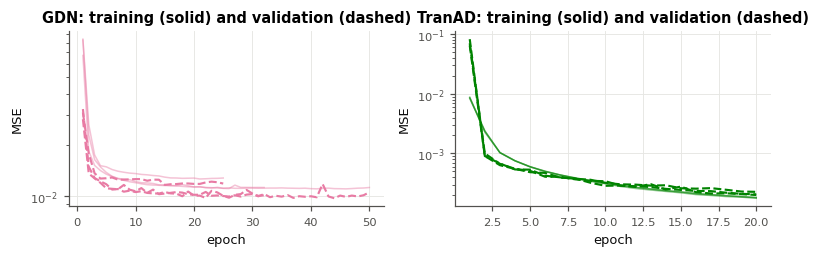

In [15]:
if len(training_histories):
    fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 2.4))
    for ax, name in zip(axes, ["GDN", "TranAD"]):
        h = training_histories[training_histories["model"] == name]
        for seed, g in h.groupby("seed"):
            st = style(name)
            ax.plot(g["epoch"], g["train_loss"], color=st["color"], lw=1.0, alpha=0.45)
            ax.plot(g["epoch"], g["val_loss"], color=st["color"], lw=1.4, ls="--")
        ax.set(yscale="log", xlabel="epoch", ylabel="MSE", title=f"{name}: training (solid) and validation (dashed)")
    plt.tight_layout()
    save_fig(fig, "deep_training_curves")
    plt.show()

## **E. Evaluation: one protocol for every method**

#### Pre-registered endpoints (fixed before looking at the baseline results)
| role | metric | why |
|---|---|---|
| **primary** | **pAUC (FPR ≤ 10%)**, McClish-standardised (0.5 = random, 1 = perfect) | threshold-free, but restricted to the operating region an operator can afford |
| **co-primary (deployable)** | at the **static CAL 1% threshold**: attacks detected, recall, false-alarm episodes per day | what a plant would actually run, with no TEST labels involved |
| secondary | ROC-AUC, average precision, median time to detect, the adaptive threshold | completeness and comparison with the TabPFN pipelines |
| **literature only** | best F1 and point-adjusted best F1 (oracle thresholds) | comparability with published tables; not used for conclusions |

**Uncertainty:** 95% CIs from the **event bootstrap** (the attacks and 1 h normal blocks are resampled separately), the honest interval with few attacks; the row-block bootstrap is reported too. A difference **TabPFN fused − baseline** is supported only if its paired event CI excludes 0.

**Methods.** TabPFN, GMM, IF and PCA each give six scores (`fused` = the primary fusion, `fused-sd`, `fused-max`, and the three views). GDN and TranAD give one score each. The **headline set** is each family's primary score: `TabPFN fused`, `GMM fused`, `IF fused`, `PCA fused`, `GDN`, `TranAD`.

In [16]:
METHODS = {}
for fam in FAMILY_ORDER:
    if fam in per_view_scores:
        fused = {s: add_fusions(per_view_scores[fam][s]) for s in SPLITS}
        for g in GROUPS:
            METHODS[f"{fam} {g}"] = {"test": fused["test"][g], "cal": fused["cal"][g], "family": fam, "group": g}
    elif fam in seq_scores:
        METHODS[fam] = {"test": seq_scores[fam]["test"], "cal": seq_scores[fam]["cal"], "family": fam, "group": "sequence"}

# Label-free TabPFN + TranAD fusion: mean of the two CAL robust-z scores (the same rule as the view fusion); threshold from CAL.
if "TabPFN fused" in METHODS and "TranAD" in METHODS:
    METHODS["TabPFN+TranAD"] = {sp: np.mean([METHODS["TabPFN fused"][sp], METHODS["TranAD"][sp]], axis=0) for sp in SPLITS}
    METHODS["TabPFN+TranAD"].update({"family": "TabPFN+TranAD", "group": "fusion"})
    _c = {r["family"]: r for r in cost_rows}
    cost_rows.append({"family": "TabPFN+TranAD", "what": "TabPFN fused + TranAD (sum of both)",
                      "ms_per_row": _c["TabPFN"]["ms_per_row"] + _c["TranAD"]["ms_per_row"], "train_s": _c["TranAD"]["train_s"]})
names = list(METHODS)
HEADLINE = [m for m in [f"{f} {EVAL_CONFIG['primary']}" for f in ["TabPFN", "GMM", "IF", "PCA", "Input", "RandAE"]] + ["GDN", "TranAD", "TabPFN+TranAD"] if m in METHODS]
PRIMARY = f"TabPFN {EVAL_CONFIG['primary']}" if f"TabPFN {EVAL_CONFIG['primary']}" in METHODS else None
for m in names:
    assert np.isfinite(METHODS[m]["test"]).all() and np.isfinite(METHODS[m]["cal"]).all(), f"non-finite scores: {m}"

target_fpr = EVAL_CONFIG["target_fpr"]
stride_s = DATA_CONFIG["test_stride"]
y_eval = y_test
ts_eval = test_df["timestamp"]
score_matrix = {m: METHODS[m]["test"] for m in names}
THRESHOLDS = {m: threshold_from_calibration(METHODS[m]["cal"], target_fpr) for m in names}
ADAPTIVE = {}
for m in names:
    z_cal, z_test = adaptive_normalise(METHODS[m]["cal"], METHODS[m]["test"], stride_s, EVAL_CONFIG)
    ADAPTIVE[m] = (z_test, threshold_from_calibration(z_cal, target_fpr))
phase_eval = np.full(len(test_df), "normal", dtype=object)
for seg in segments.itertuples(index=False):
    inside = ts_eval.between(seg.start, seg.end).to_numpy()
    since = (ts_eval - seg.start).dt.total_seconds().to_numpy()
    phase_eval[inside] = np.where(since[inside] < EVAL_CONFIG["onset_s"], "onset", "sustained")
normal_test_days = (y_eval == 0).sum() * stride_s / 86400

for split, frame in SPLITS.items():
    extra = ["is_attack", "attack_id"] if split == "test" else []
    out = frame[["timestamp"] + extra].copy()
    for m in names:
        out[m] = METHODS[m][split]
    out.to_parquet(RUN_DIR / f"scores_{split}.parquet", index=False)
segments.to_csv(RUN_DIR / "attack_segments.csv", index=False)
cost = pd.DataFrame(cost_rows)
cost.to_csv(RUN_DIR / "results_cost.csv", index=False)
print(f"{DATASET}: TEST {len(y_eval):,} rows ({y_eval.sum():,} attack, {y_eval.mean():.1%}), {len(segments)} attacks, "
      f"{normal_test_days:.2f} normal days | target FPR {target_fpr}")
print(f"Methods ({len(names)}). Headline: {HEADLINE} | primary: {PRIMARY}")

HAI 21.03: TEST 40,201 rows (887 attack, 2.2%), 50 attacks, 4.55 normal days | target FPR 0.01
Methods (39). Headline: ['TabPFN fused', 'GMM fused', 'IF fused', 'PCA fused', 'Input fused', 'RandAE fused', 'GDN', 'TranAD', 'TabPFN+TranAD'] | primary: TabPFN fused


### **E1. Main results: every method at the static and adaptive CAL thresholds**

In [17]:
rows, per_event_tables = [], {}
for method in names:
    s = score_matrix[method]
    auc, pauc, ap = curve_metrics(y_eval, s, EVAL_CONFIG["pauc_max_fpr"])
    oracle, oracle_pa = best_f1(y_eval, s), point_adjusted_best_f1(y_eval, s)
    for mode, (scores, thr) in {"static": (s, THRESHOLDS[method]), "adaptive": ADAPTIVE[method]}.items():
        scores = finite(scores)
        pred = scores >= thr
        point = point_metrics(y_eval, scores, thr)
        event, per_event = event_metrics(ts_eval, y_eval, pred, segments)
        per_event_tables[(method, mode)] = per_event
        rows.append({"method": method, "family": METHODS[method]["family"], "group": METHODS[method]["group"],
                     "threshold_mode": mode, "threshold": thr, **point, f"pauc_fpr<={EVAL_CONFIG['pauc_max_fpr']}": pauc,
                     **event, "false_alarms_per_day": event["false_alarm_episodes"] / normal_test_days,
                     "recall_onset": pred[phase_eval == "onset"].mean(), "recall_sustained": pred[phase_eval == "sustained"].mean(),
                     "tpr@fpr=1% (oracle)": tpr_at_fpr(y_eval, s, 0.01),
                     "best_f1 (oracle)": oracle["f1"], "pa_best_f1 (oracle)": oracle_pa["f1"]})
main_results = pd.DataFrame(rows)
main_results.insert(0, "dataset", DATASET)
main_results.insert(1, "run_fingerprint", RUN_FINGERPRINT)
main_results.to_csv(RUN_DIR / "results_main.csv", index=False)
PAUC_COL = f"pauc_fpr<={EVAL_CONFIG['pauc_max_fpr']}"
show_cols = [PAUC_COL, "roc_auc", "average_precision", "test_fpr", "recall", "precision", "attacks_detected",
             "false_alarms_per_day", "median_ttd_s", "recall_onset", "recall_sustained", "composite_f1"]
for mode in ["static", "adaptive"]:
    print(f"--- {mode} CAL threshold (target FPR {target_fpr:.0%}) ---")
    display(main_results[main_results["threshold_mode"] == mode].set_index("method")[show_cols].round(4))

--- static CAL threshold (target FPR 1%) ---


,pauc_fpr<=0.1,roc_auc,average_precision,test_fpr,recall,precision,attacks_detected,false_alarms_per_day,median_ttd_s,recall_onset,recall_sustained,composite_f1
method,,,,,,,,,,,,
TabPFN fused,0.8098,0.9143,0.4435,0.0209,0.5784,0.3843,42,46.8108,26.0,0.5017,0.6166,0.5273
TabPFN fused-sd,0.8161,0.9177,0.4375,0.0201,0.5908,0.3982,43,62.6342,26.0,0.5017,0.6351,0.5443
TabPFN fused-max,0.7664,0.8952,0.3216,0.0228,0.4577,0.3118,39,40.4375,26.0,0.4034,0.4848,0.4455
TabPFN state,0.7918,0.8891,0.4698,0.0479,0.6212,0.2262,45,205.0445,16.0,0.5661,0.6486,0.3615
TabPFN detrend,0.7301,0.8763,0.2644,0.0211,0.2818,0.2313,28,18.0211,46.5,0.1831,0.3311,0.3273
TabPFN dynamics,0.7598,0.8888,0.2425,0.0113,0.3224,0.3912,32,19.3397,36.5,0.2983,0.3345,0.4856
GMM fused,0.7777,0.8997,0.3036,0.0562,0.7542,0.2324,47,47.2503,16.0,0.6983,0.7821,0.3726
GMM fused-sd,0.8017,0.9011,0.2991,0.0396,0.7091,0.2879,46,40.8770,15.5,0.6576,0.7348,0.4385
GMM fused-max,0.7523,0.8864,0.2812,0.0574,0.7024,0.2163,46,42.8550,15.5,0.6814,0.7128,0.3503


--- adaptive CAL threshold (target FPR 1%) ---


,pauc_fpr<=0.1,roc_auc,average_precision,test_fpr,recall,precision,attacks_detected,false_alarms_per_day,median_ttd_s,recall_onset,recall_sustained,composite_f1
method,,,,,,,,,,,,
TabPFN fused,0.8098,0.9019,0.3729,0.0273,0.5254,0.3024,41,67.4691,26.0,0.4746,0.5507,0.4419
TabPFN fused-sd,0.8161,0.9049,0.3568,0.0217,0.4994,0.3413,43,63.2935,26.0,0.4949,0.5017,0.4887
TabPFN fused-max,0.7664,0.8838,0.2868,0.0160,0.3529,0.3323,34,28.5700,32.5,0.3186,0.3699,0.4464
TabPFN state,0.7918,0.8821,0.3621,0.0131,0.4070,0.4121,41,59.1179,27.0,0.4102,0.4054,0.5485
TabPFN detrend,0.7301,0.8701,0.2450,0.0174,0.2424,0.2392,22,14.9443,46.0,0.1492,0.2889,0.3099
TabPFN dynamics,0.7598,0.8833,0.2259,0.0139,0.3517,0.3628,33,28.5700,37.0,0.3220,0.3666,0.4682
GMM fused,0.7777,0.9012,0.2980,0.0525,0.7170,0.2355,46,46.8108,16.0,0.6746,0.7382,0.3750
GMM fused-sd,0.8017,0.9027,0.2951,0.0363,0.6460,0.2864,46,38.0200,16.0,0.6508,0.6436,0.4368
GMM fused-max,0.7523,0.8851,0.2751,0.0495,0.6212,0.2208,46,31.4270,16.0,0.6271,0.6182,0.3561


### **E2. Operating curves: attacks found vs. false alarms per day**

The threshold sweeps the CAL quantile from 0.1% to 10% target FPR. Each point is a deployable detector (no TEST labels involved). Left: what an operator sees, attacks found against false-alarm episodes per day of normal operation. Right: the ROC restricted to FPR ≤ 10%, with ● the static CAL 1% operating point.

target_fpr,0.01
method,
TabPFN fused,42
TabPFN fused-sd,43
TabPFN fused-max,39
TabPFN state,45
TabPFN detrend,28
TabPFN dynamics,32
GMM fused,47
GMM fused-sd,46
GMM fused-max,46


figure saved: output-figures/operating_curves_hai2103_baselines.png


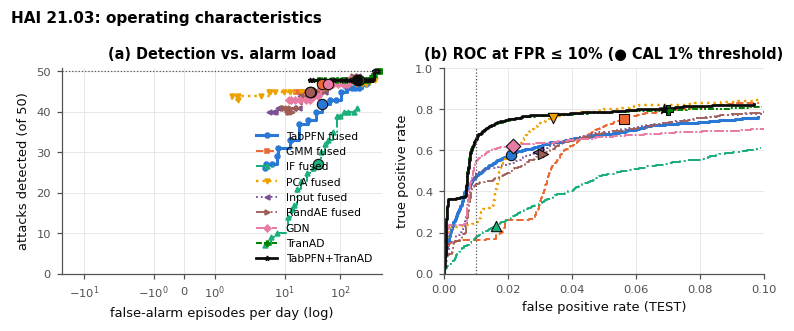

In [18]:
op_rows = []
for fpr_target in EVAL_CONFIG["operating_fprs"]:
    for m in names:
        thr = threshold_from_calibration(METHODS[m]["cal"], fpr_target)
        pred = score_matrix[m] >= thr
        ev, _ = event_metrics(ts_eval, y_eval, pred, segments)
        op_rows.append({"method": m, "target_fpr": fpr_target, "test_fpr": pred[y_eval == 0].mean(),
                        "recall": pred[y_eval == 1].mean(), "attacks_detected": ev["attacks_detected"],
                        "false_alarms_per_day": ev["false_alarm_episodes"] / normal_test_days})
operating = pd.DataFrame(op_rows)
operating.to_csv(RUN_DIR / "results_operating_curves.csv", index=False)
display(operating[operating["target_fpr"].isin(EVAL_CONFIG["fpr_grid"])]
        .pivot(index="method", columns="target_fpr", values="attacks_detected").loc[names])

fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 3.0))
for m in HEADLINE:
    st = style(m)
    op = operating[operating["method"] == m].sort_values("target_fpr")
    axes[0].plot(op["false_alarms_per_day"], op["attacks_detected"], color=st["color"], ls=st["ls"], lw=st["lw"],
                 marker=st["marker"], ms=3.2, drawstyle="steps-post", label=m)
    at = op.iloc[(op["target_fpr"] - target_fpr).abs().argmin()]
    axes[0].scatter(at["false_alarms_per_day"], at["attacks_detected"], s=46, color=st["color"], edgecolor=INK, lw=0.7, zorder=5)
    f, t_, _ = roc_curve(y_eval, score_matrix[m])
    keep = f <= EVAL_CONFIG["pauc_max_fpr"] + 1e-9
    axes[1].plot(f[keep], t_[keep], color=st["color"], ls=st["ls"], lw=st["lw"], label=m)
    r = main_results[(main_results["method"] == m) & (main_results["threshold_mode"] == "static")].iloc[0]
    axes[1].scatter(r["test_fpr"], r["recall"], s=46, color=st["color"], marker=st["marker"], edgecolor=INK, lw=0.7, zorder=5)
axes[0].axhline(len(segments), color=MUTED, lw=0.8, ls=":")
axes[0].set(xscale="symlog", xlabel="false-alarm episodes per day (log)", ylabel=f"attacks detected (of {len(segments)})",
            title="(a) Detection vs. alarm load", ylim=(0, len(segments) + 0.8))
axes[1].axvline(target_fpr, color=MUTED, lw=0.8, ls=":")
axes[1].set(xlim=(0, EVAL_CONFIG["pauc_max_fpr"]), ylim=(0, 1), xlabel="false positive rate (TEST)", ylabel="true positive rate",
            title="(b) ROC at FPR ≤ 10% (● CAL 1% threshold)")
axes[0].legend(loc="lower right", fontsize=7)
fig.suptitle(f"{DATASET}: operating characteristics", x=0.01, ha="left", fontsize=10, fontweight="bold")
plt.tight_layout()
save_fig(fig, "operating_curves")
plt.show()

### **E3. Uncertainty: event and block bootstraps, paired differences against TabPFN**

Every method is scored on **the same replicate indices**, so the paired differences come straight from the replicates. Thresholded metrics keep the CAL threshold fixed (it never sees TEST). The event bootstrap also gives the CI of **attacks detected** (event recall), resampling whole attacks.

In [19]:
%%time
rng = np.random.default_rng(EVAL_CONFIG["bootstrap_seed"])
block = EVAL_CONFIG["bootstrap_block_rows"]
attack_units = [np.arange(a, b) for a, b in contiguous_runs(y_eval == 1)]
normal_units = [np.arange(a, b)[i:i + block] for a, b in contiguous_runs(y_eval == 0) for i in range(0, b - a, block)]
static_pred = {m: score_matrix[m] >= THRESHOLDS[m] for m in names}
unit_detected = {m: np.array([static_pred[m][u].any() for u in attack_units]) for m in names}
print(f"Event bootstrap units: {len(attack_units)} attacks, {len(normal_units)} normal blocks")

boot = {"block": [], "event": []}
for _ in range(EVAL_CONFIG["bootstrap_repeats"]):
    idx_block = block_bootstrap_indices(len(y_eval), block, rng)
    idx_event, pick_a = event_bootstrap_indices(attack_units, normal_units, rng)
    for kind, idx in [("block", idx_block), ("event", idx_event)]:
        yb = y_eval[idx].astype(bool)
        if yb.all() or not yb.any():
            continue
        rec = {}
        for m in names:
            rec[f"auc|{m}"], rec[f"pauc|{m}"], rec[f"ap|{m}"] = curve_metrics(yb, score_matrix[m][idx], EVAL_CONFIG["pauc_max_fpr"])
            pb = static_pred[m][idx]
            rec[f"recall|{m}"], rec[f"fpr|{m}"] = pb[yb].mean(), pb[~yb].mean()
            if kind == "event":
                rec[f"event_recall|{m}"] = unit_detected[m][pick_a].mean()
        boot[kind].append(rec)
boot = {k: pd.DataFrame(v) for k, v in boot.items()}
for kind, frame in boot.items():
    frame.to_parquet(RUN_DIR / f"bootstrap_replicates_{kind}.parquet", index=False)

METRICS = {"pauc": "pAUC (FPR ≤ 10%)", "auc": "ROC-AUC", "ap": "average precision", "recall": "recall @ CAL 1%",
           "fpr": "test FPR @ CAL 1%", "event_recall": "attacks detected @ CAL 1% (share)"}
static = main_results[main_results["threshold_mode"] == "static"].set_index("method")
point_value = {"pauc": static[PAUC_COL], "auc": static["roc_auc"], "ap": static["average_precision"],
               "recall": static["recall"], "fpr": static["test_fpr"], "event_recall": static["event_recall"]}
ci_rows = []
for m in names:
    for key, label in METRICS.items():
        row = {"method": m, "metric": label, "key": key, "estimate": float(point_value[key][m])}
        for kind in boot:
            col = f"{key}|{m}"
            if col in boot[kind]:
                row[f"{kind}_ci_low"], row[f"{kind}_ci_high"] = np.quantile(boot[kind][col], [0.025, 0.975])
        ci_rows.append(row)
ci_table = pd.DataFrame(ci_rows)
ci_table.to_csv(RUN_DIR / "results_bootstrap_ci.csv", index=False)
print({k: len(v) for k, v in boot.items()}, "replicates")
display(ci_table[ci_table["method"].isin(HEADLINE)].set_index(["method", "metric"]).drop(columns="key").round(4))

diff_rows = []
if PRIMARY:
    for b in [m for m in names if m != PRIMARY]:
        for key, label in METRICS.items():
            row = {"comparison": f"{PRIMARY} − {b}", "baseline": b, "metric": label, "key": key,
                   "delta": float(point_value[key][PRIMARY] - point_value[key][b])}
            for kind in boot:
                if f"{key}|{PRIMARY}" in boot[kind]:
                    d = boot[kind][f"{key}|{PRIMARY}"] - boot[kind][f"{key}|{b}"]
                    row[f"{kind}_ci_low"], row[f"{kind}_ci_high"] = np.quantile(d, [0.025, 0.975])
                    row[f"{kind}_ci_excludes_0"] = not (row[f"{kind}_ci_low"] <= 0 <= row[f"{kind}_ci_high"])
            diff_rows.append(row)
paired = pd.DataFrame(diff_rows)
paired.to_csv(RUN_DIR / "results_paired_differences.csv", index=False)
if PRIMARY:
    display(paired[paired["baseline"].isin(HEADLINE) & paired["key"].isin(["pauc", "auc", "recall", "event_recall"])]
            .set_index(["baseline", "metric"]).drop(columns=["comparison", "key"]).round(4))
else:
    print("No TabPFN scores: paired differences skipped.")

Event bootstrap units: 50 attacks, 134 normal blocks
{'block': 1000, 'event': 1000} replicates


estimate  block_ci_low  \
method        metric                                                      
TabPFN fused  pAUC (FPR ≤ 10%)                     0.8098        0.7618   
              ROC-AUC                              0.9143        0.8806   
              average precision                    0.4435        0.3429   
              recall @ CAL 1%                      0.5784        0.4645   
              test FPR @ CAL 1%                    0.0209        0.0150   
              attacks detected @ CAL 1% (share)    0.8400           NaN   
GMM fused     pAUC (FPR ≤ 10%)                     0.7777        0.7200   
              ROC-AUC                              0.8997        0.8603   
              average precision                    0.3036        0.2120   
              recall @ CAL 1%                      0.7542        0.6724   
              test FPR @ CAL 1%                    0.0562        0.0356   
              attacks detected @ CAL 1% (share)    0.9400           NaN   
IF fused      pAUC (FPR ≤ 10%)                     0.6940        0.6515   
              ROC-AUC                              0.8283        0.7767   
              average precision                    0.1775        0.1165   
              recall @ CAL 1%                      0.2300        0.1540   
              test FPR @ CAL 1%                    0.0163        0.0116   
              attacks detected @ CAL 1% (share)    0.5400           NaN   
PCA fused     pAUC (FPR ≤ 10%)                     0.8382        0.7985   
              ROC-AUC                              0.9148        0.8754   
              average precision                    0.4177        0.3214   
              recall @ CAL 1%                      0.7599        0.6693   
              test FPR @ CAL 1%                    0.0341        0.0236   
              attacks detected @ CAL 1% (share)    0.9000           NaN   
Input fused   pAUC (FPR ≤ 10%)                     0.8068        0.7662   
              ROC-AUC                              0.8906        0.8440   
              average precision                    0.3918        0.2980   
              recall @ CAL 1%                      0.5908        0.4893   
              test FPR @ CAL 1%                    0.0296        0.0202   
              attacks detected @ CAL 1% (share)    0.9000           NaN   
RandAE fused  pAUC (FPR ≤ 10%)                     0.7989        0.7590   
              ROC-AUC                              0.8892        0.8440   
              average precision                    0.3530        0.2602   
              recall @ CAL 1%                      0.5829        0.4814   
              test FPR @ CAL 1%                    0.0311        0.0212   
              attacks detected @ CAL 1% (share)    0.9000           NaN   
GDN           pAUC (FPR ≤ 10%)                     0.8016        0.7570   
              ROC-AUC                              0.8489        0.7999   
              average precision                    0.4257        0.3009   
              recall @ CAL 1%                      0.6234        0.5284   
              test FPR @ CAL 1%                    0.0216        0.0134   
              attacks detected @ CAL 1% (share)    0.9400           NaN   
TranAD        pAUC (FPR ≤ 10%)                     0.8637        0.8185   
              ROC-AUC                              0.9031        0.8587   
              average precision                    0.5608        0.4355   
              recall @ CAL 1%                      0.7959        0.7119   
              test FPR @ CAL 1%                    0.0702        0.0519   
              attacks detected @ CAL 1% (share)    0.9600           NaN   
TabPFN+TranAD pAUC (FPR ≤ 10%)                     0.8681        0.8216   
              ROC-AUC                              0.9202        0.8840   
              average precision                    0.5667        0.4407   
              recall @ CAL 1%                      0.8038        0.7166   

delta  block_ci_low  \
baseline      metric                                                    
GMM fused     pAUC (FPR ≤ 10%)                   0.0321       -0.0251   
              ROC-AUC                            0.0146       -0.0078   
              recall @ CAL 1%                   -0.1759       -0.2553   
              attacks detected @ CAL 1% (share) -0.1000           NaN   
IF fused      pAUC (FPR ≤ 10%)                   0.1158        0.0812   
              ROC-AUC                            0.0860        0.0532   
              recall @ CAL 1%                    0.3484        0.2482   
              attacks detected @ CAL 1% (share)  0.3000           NaN   
PCA fused     pAUC (FPR ≤ 10%)                  -0.0284       -0.0686   
              ROC-AUC                           -0.0005       -0.0228   
              recall @ CAL 1%                   -0.1815       -0.2699   
              attacks detected @ CAL 1% (share) -0.0600           NaN   
Input fused   pAUC (FPR ≤ 10%)                   0.0030       -0.0232   
              ROC-AUC                            0.0237       -0.0051   
              recall @ CAL 1%                   -0.0124       -0.0771   
              attacks detected @ CAL 1% (share) -0.0600           NaN   
RandAE fused  pAUC (FPR ≤ 10%)                   0.0109       -0.0166   
              ROC-AUC                            0.0251       -0.0035   
              recall @ CAL 1%                   -0.0045       -0.0697   
              attacks detected @ CAL 1% (share) -0.0600           NaN   
GDN           pAUC (FPR ≤ 10%)                   0.0081       -0.0250   
              ROC-AUC                            0.0654        0.0347   
              recall @ CAL 1%                   -0.0451       -0.1147   
              attacks detected @ CAL 1% (share) -0.1000           NaN   
TranAD        pAUC (FPR ≤ 10%)                  -0.0539       -0.0884   
              ROC-AUC                            0.0111       -0.0144   
              recall @ CAL 1%                   -0.2176       -0.2904   
              attacks detected @ CAL 1% (share) -0.1200           NaN   
TabPFN+TranAD pAUC (FPR ≤ 10%)                  -0.0583       -0.0936   
              ROC-AUC                           -0.0059       -0.0241   
              recall @ CAL 1%                   -0.2255       -0.2966   
              attacks detected @ CAL 1% (share) -0.1200           NaN   

                                                 block_ci_high  \
baseline      metric                                             
GMM fused     pAUC (FPR ≤ 10%)                          0.0912   
              ROC-AUC                                   0.0375   
              recall @ CAL 1%                          -0.1049   
              attacks detected @ CAL 1% (share)            NaN   
IF fused      pAUC (FPR ≤ 10%)                          0.1532   
              ROC-AUC                                   0.1241   
              recall @ CAL 1%                           0.4391   
              attacks detected @ CAL 1% (share)            NaN   
PCA fused     pAUC (FPR ≤ 10%)                          0.0070   
              ROC-AUC                                   0.0266   
              recall @ CAL 1%                          -0.1072   
              attacks detected @ CAL 1% (share)            NaN   
Input fused   pAUC (FPR ≤ 10%)                          0.0273   
              ROC-AUC                                   0.0592   
              recall @ CAL 1%                           0.0536   
              attacks detected @ CAL 1% (share)            NaN   
RandAE fused  pAUC (FPR ≤ 10%)                          0.0357   
              ROC-AUC                                   0.0600   
              recall @ CAL 1%                           0.0637   
              attacks detected @ CAL 1% (share)            NaN   
GDN           pAUC (FPR ≤ 10%)                          0.0443   
              ROC-AUC                            

CPU times: user 3min 5s, sys: 72 ms, total: 3min 5s
Wall time: 3min 5s


figure saved: output-figures/paired_differences_hai2103_baselines.png


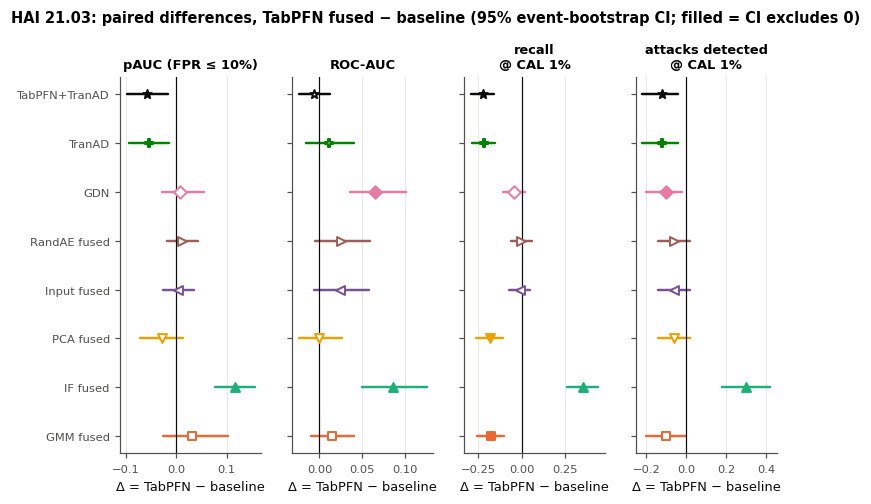

figure saved: output-figures/forest_all_methods_hai2103_baselines.png


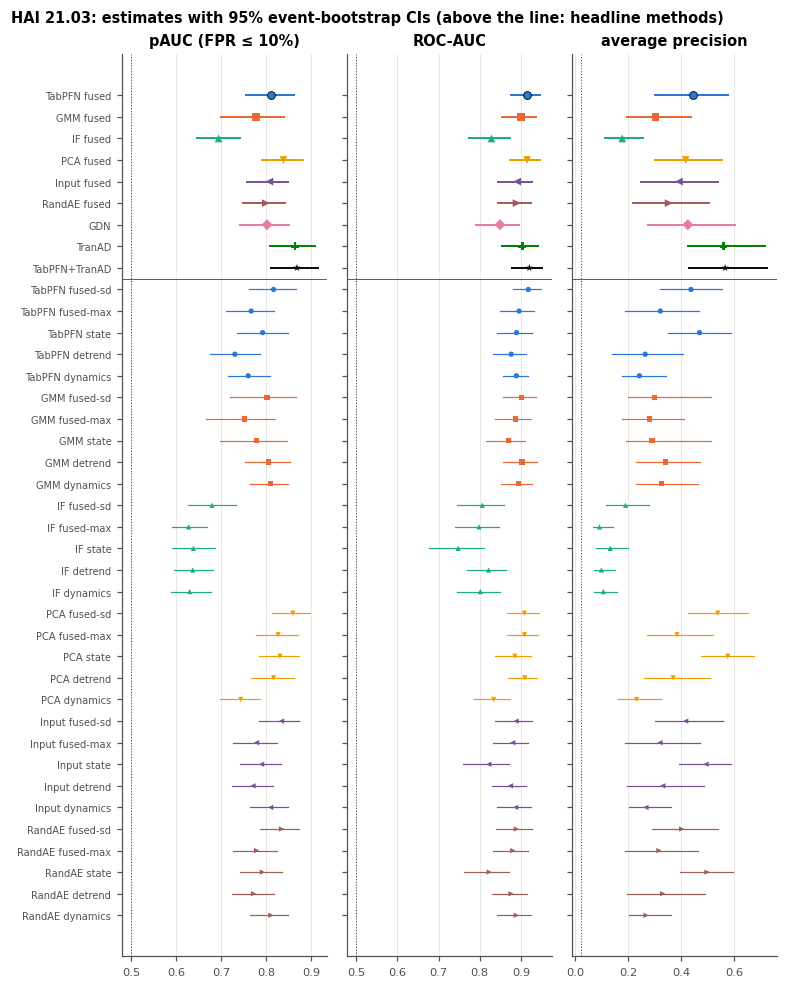

In [20]:
# Paper figure 1: paired differences TabPFN fused − each headline baseline (event bootstrap).
if PRIMARY:
    keys = ["pauc", "auc", "recall", "event_recall"]
    baselines = [m for m in HEADLINE if m != PRIMARY]
    fig, axes = plt.subplots(1, len(keys), figsize=(FULL_W, 0.42 * len(baselines) + 1.25), sharey=True)
    for ax, key in zip(axes, keys):
        sub = paired[(paired["key"] == key)].set_index("baseline").loc[baselines]
        ypos = np.arange(len(baselines))
        for y, (b, r) in zip(ypos, sub.iterrows()):
            st = style(b)
            filled = bool(r.get("event_ci_excludes_0", False))
            ax.plot([r["event_ci_low"], r["event_ci_high"]], [y, y], color=st["color"], lw=1.6, solid_capstyle="round")
            ax.scatter(r["delta"], y, s=34, marker=st["marker"], color=st["color"] if filled else "white",
                       edgecolor=st["color"], lw=1.3, zorder=4)
        ax.axvline(0, color=INK, lw=0.8)
        ax.set_title(METRICS[key].replace(" @ CAL 1%", "\n@ CAL 1%").replace(" (share)", ""), fontsize=8.5)
        ax.set_yticks(ypos)
        ax.set_yticklabels(baselines)
        ax.invert_yaxis()
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("Δ = TabPFN − baseline")
    fig.suptitle(f"{DATASET}: paired differences, {PRIMARY} − baseline (95% event-bootstrap CI; filled = CI excludes 0)",
                 x=0.01, ha="left", fontsize=9.5, fontweight="bold")
    plt.tight_layout()
    save_fig(fig, "paired_differences")
    plt.show()

# Paper figure 2: forest plot of the primary and secondary metrics for every method.
order = HEADLINE + [m for m in names if m not in HEADLINE]
fig, axes = plt.subplots(1, 3, figsize=(FULL_W, 0.2 * len(order) + 1.3), sharey=True)
for ax, key in zip(axes, ["pauc", "auc", "ap"]):
    sub = ci_table[ci_table["key"] == key].set_index("method").loc[order]
    ypos = np.arange(len(order))
    for y, (m, r) in zip(ypos, sub.iterrows()):
        st = style(m)
        ax.plot([r["event_ci_low"], r["event_ci_high"]], [y, y], color=st["color"], lw=1.3 if m in HEADLINE else 0.8)
        ax.scatter(r["estimate"], y, s=26 if m in HEADLINE else 12, marker=st["marker"], color=st["color"], zorder=4,
                   edgecolor=INK if m == PRIMARY else "none", lw=0.6)
    if key in ("pauc", "auc"):
        ax.axvline(0.5, color=MUTED, lw=0.7, ls=":")
    else:
        ax.axvline(y_eval.mean(), color=MUTED, lw=0.7, ls=":")
    ax.axhline(len(HEADLINE) - 0.5, color=MUTED, lw=0.6)
    ax.set_title(METRICS[key])
    ax.set_yticks(ypos)
    ax.set_yticklabels(order, fontsize=6.5)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
fig.suptitle(f"{DATASET}: estimates with 95% event-bootstrap CIs (above the line: headline methods)",
             x=0.01, ha="left", fontsize=9.5, fontweight="bold")
plt.tight_layout()
save_fig(fig, "forest_all_methods")
plt.show()

### **E4. Which attacks does each method find? (static CAL 1% threshold)**

Cell colour = share of the attack's TEST rows alarmed; text = time to first alarm (s), or – if never alarmed. The last column is the **diagnostic** "an actuator is in a state never seen in FIT" rule: it is not a method, it shows which attacks a trivial rule exposes.

figure saved: output-figures/per_attack_detection_hai2103_baselines.png


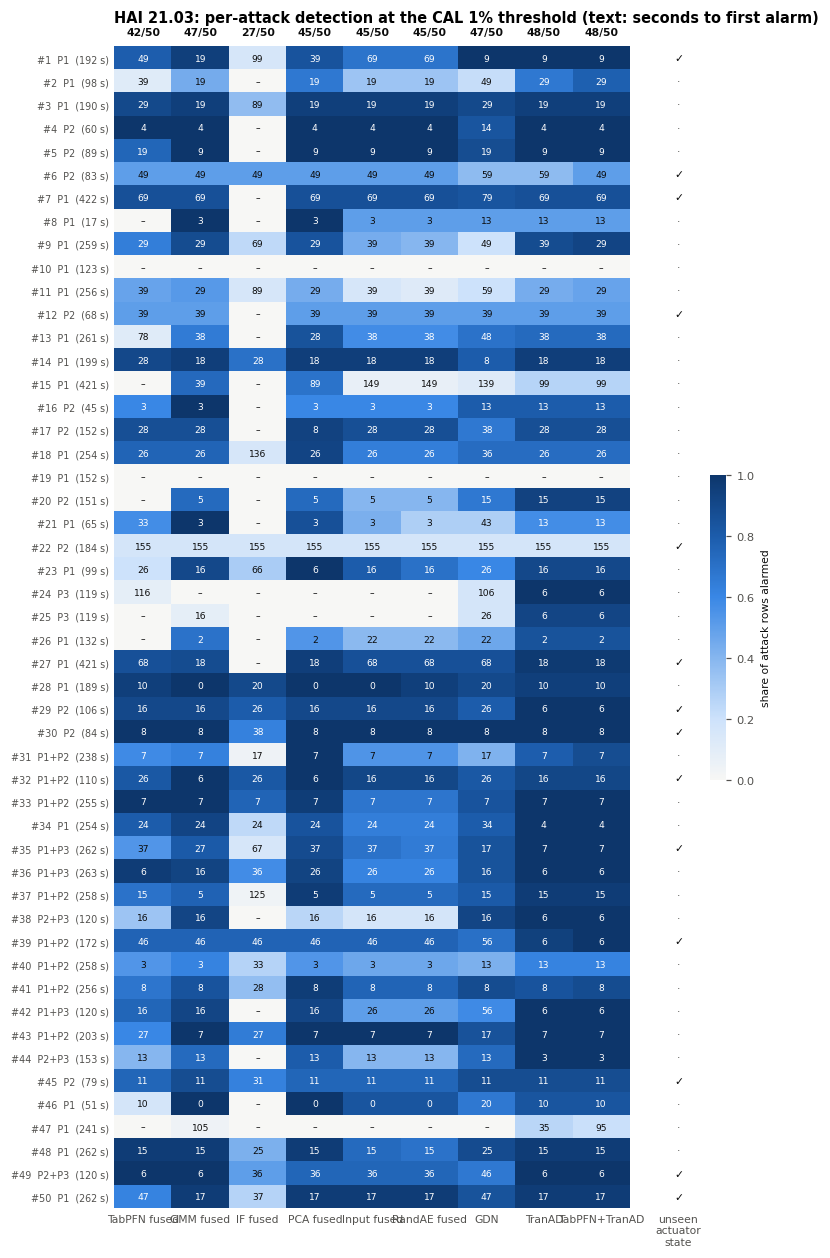

Complementarity with TabPFN fused (attacks found by the union of two detectors):


,added to TabPFN fused,attacks only it finds,union attacks
0,GMM fused,6,48
1,IF fused,0,42
2,PCA fused,4,46
3,Input fused,4,46
4,RandAE fused,4,46
5,GDN,5,47
6,TranAD,6,48
7,TabPFN+TranAD,6,48
8,unseen actuator state (diagnostic),0,42


In [21]:
event_view = per_event_tables[(names[0], "static")][["segment", "attack_id", "attack_point", "start", "duration_s"]].copy()
for m in names:
    event_view[f"{m} detected"] = per_event_tables[(m, "static")]["detected"].to_numpy()
    event_view[f"{m} TTD (s)"] = per_event_tables[(m, "static")]["time_to_detect_s"].to_numpy()
ts_index = pd.DatetimeIndex(ts_eval)
event_view["unseen actuator state (diagnostic)"] = [
    bool(UNSEEN_ROWS[ts_index.searchsorted(s.start):ts_index.searchsorted(s.end, side="right")].any())
    for s in segments.itertuples(index=False)]
event_view.to_csv(RUN_DIR / "results_per_attack.csv", index=False)

frac = np.column_stack([per_event_tables[(m, "static")]["fraction_alarmed"].to_numpy() for m in HEADLINE])
ttd = np.column_stack([per_event_tables[(m, "static")]["time_to_detect_s"].to_numpy() for m in HEADLINE])
labels = [f"#{r.attack_id}  {str(r.attack_point)[:22]}  ({int(r.duration_s)} s)" for r in event_view.itertuples()]
n_att = len(labels)
fig, ax = plt.subplots(figsize=(FULL_W, 0.2 * n_att + 1.5))
im = ax.imshow(frac, cmap=SEQ_BLUE, vmin=0, vmax=1, aspect="auto")
for i in range(n_att):
    for j in range(len(HEADLINE)):
        txt = "–" if np.isnan(ttd[i, j]) else f"{ttd[i, j]:.0f}"
        ax.text(j, i, txt, ha="center", va="center", fontsize=6, color="white" if frac[i, j] > 0.55 else INK)
diag = event_view["unseen actuator state (diagnostic)"].to_numpy()
jd = len(HEADLINE) + 0.35
for i in range(n_att):
    ax.text(jd, i, "✓" if diag[i] else "·", ha="center", va="center", fontsize=7, color=INK if diag[i] else MUTED)
ax.set_xlim(-0.5, len(HEADLINE) + 0.8)
ax.set_xticks(list(range(len(HEADLINE))) + [jd])
ax.set_xticklabels(HEADLINE + ["unseen\nactuator\nstate"], rotation=0, fontsize=7)
ax.set_yticks(range(n_att))
ax.set_yticklabels(labels, fontsize=6.3)
ax.grid(False)
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
detected_counts = [int(per_event_tables[(m, "static")]["detected"].sum()) for m in HEADLINE]
for j, c in enumerate(detected_counts):
    ax.text(j, -0.9, f"{c}/{n_att}", ha="center", va="bottom", fontsize=7, fontweight="bold", color=INK)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
cb.set_label("share of attack rows alarmed", fontsize=7)
cb.outline.set_visible(False)
ax.set_title(f"{DATASET}: per-attack detection at the CAL 1% threshold (text: seconds to first alarm)", loc="left", pad=16)
plt.tight_layout()
save_fig(fig, "per_attack_detection")
plt.show()

union_rows = []
for m in [mm for mm in HEADLINE if mm != PRIMARY] + ["unseen actuator state (diagnostic)"]:
    col = event_view[f"{m} detected"] if m in METHODS else event_view[m]
    if PRIMARY:
        both = event_view[f"{PRIMARY} detected"] | col
        union_rows.append({"added to TabPFN fused": m, "attacks only it finds": int((col & ~event_view[f"{PRIMARY} detected"]).sum()),
                           "union attacks": int(both.sum())})
if union_rows:
    print("Complementarity with TabPFN fused (attacks found by the union of two detectors):")
    display(pd.DataFrame(union_rows))

### **E5. Score timelines over the attack period (headline methods)**

figure saved: output-figures/score_timelines_hai2103_baselines.png


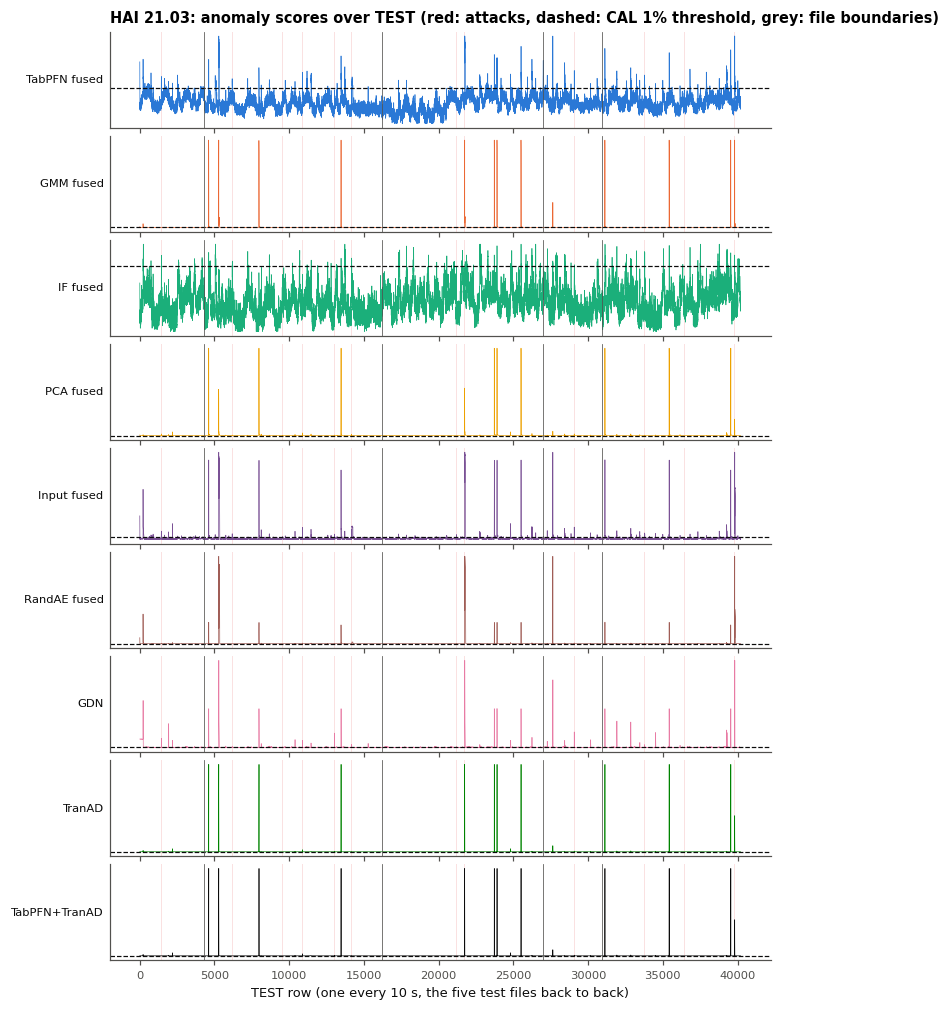

In [22]:
ts_index = pd.DatetimeIndex(ts_eval)
seg_rows = [(ts_index.searchsorted(s.start), ts_index.searchsorted(s.end, side="right")) for s in segments.itertuples(index=False)]
file_breaks = np.flatnonzero(ts_index.to_series().diff().dt.total_seconds().to_numpy() != stride_s)[1:]   # TEST is five separate files
x = np.arange(len(ts_eval))
fig, axes = plt.subplots(len(HEADLINE), 1, figsize=(FULL_W, 0.95 * len(HEADLINE) + 0.7), sharex=True)
for ax, m in zip(np.atleast_1d(axes), HEADLINE):
    s = score_matrix[m]
    lo, hi = np.quantile(s, 0.001), max(np.quantile(s, 0.999), 1.5 * THRESHOLDS[m])
    st = style(m)
    for a, b in seg_rows:
        ax.axvspan(a, b, color=ATTACK_SHADE, alpha=0.16, lw=0)
    ax.plot(x, np.clip(s, lo, hi), lw=0.45, color=st["color"])
    ax.axhline(THRESHOLDS[m], color=INK, lw=0.8, ls="--")
    for k in file_breaks:
        ax.axvline(k, color=MUTED, lw=0.5)
    ax.set_ylabel(m, rotation=0, ha="right", va="center", fontsize=7.5)
    ax.set_yticks([])
    ax.grid(False)
np.atleast_1d(axes)[0].set_title(f"{DATASET}: anomaly scores over TEST (red: attacks, dashed: CAL 1% threshold, grey: file boundaries)", loc="left")
np.atleast_1d(axes)[-1].set_xlabel("TEST row (one every 10 s, the five test files back to back)")
plt.tight_layout(h_pad=0.2)
save_fig(fig, "score_timelines")
plt.show()

### **E6. False alarms per test day, rank agreement, and cost**

figure saved: output-figures/daily_false_alarm_rate_hai2103_baselines.png


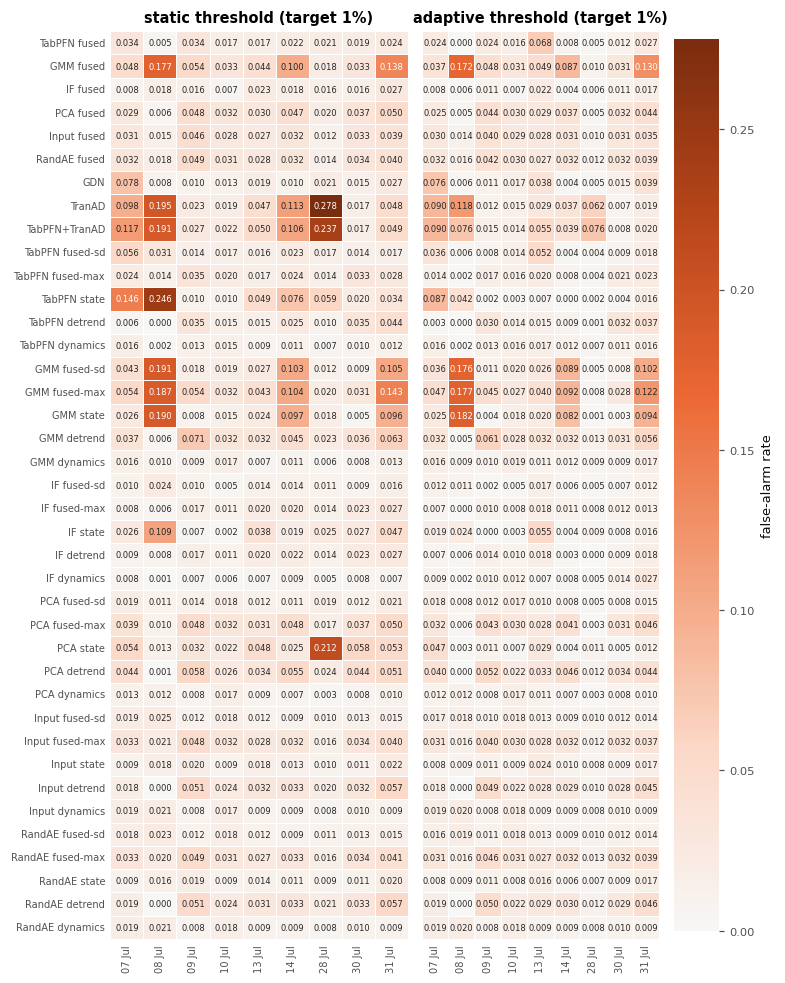

figure saved: output-figures/rank_agreement_hai2103_baselines.png


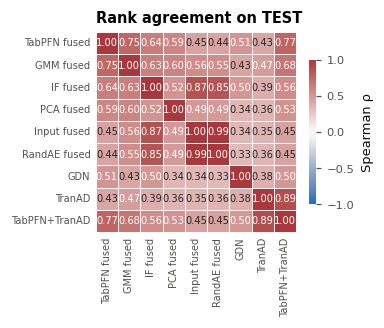

figure saved: output-figures/quality_vs_cost_hai2103_baselines.png


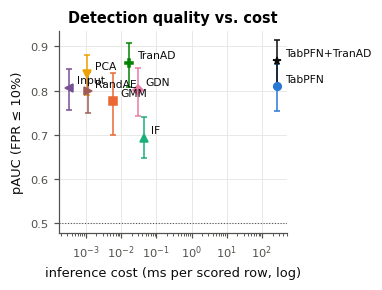

,family,what,ms_per_row,train_s
0,TabPFN,"3 views × 3 seeds, GPU",269.7926,0.0000
1,GMM,"3 views, k by BIC, CPU (reference run)",0.0059,NaN
2,IF,"3 views × 3 seeds, CPU",0.0434,3.2459
3,PCA,"3 views, CPU",0.0011,0.2230
4,Input,"3 views, L2 norm of the standardised input, CPU",0.0003,0.0000
5,RandAE,"3 views × 3 seeds, untrained, CPU",0.0011,0.0000
6,GDN,"3 seeds, GPU, batched",0.0299,165.9518
7,TranAD,"3 seeds, GPU, batched",0.0170,129.5462
8,TabPFN+TranAD,TabPFN fused + TranAD (sum of both),269.8096,129.5462


In [23]:
daily = {mode: pd.DataFrame({m: daily_false_alarm_rate(ts_eval, y_eval, finite(s) >= t)
                             for m, (s, t) in src.items()}).T
         for mode, src in {"static": {m: (score_matrix[m], THRESHOLDS[m]) for m in names}, "adaptive": ADAPTIVE}.items()}
for mode, frame in daily.items():
    frame.columns = [pd.Timestamp(c).strftime("%d %b") for c in frame.columns]
    frame.to_csv(RUN_DIR / f"results_daily_false_alarm_rate_{mode}.csv")
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 0.2 * len(order) + 1.2), sharey=True)
vmax = max(0.05, float(np.nanmax([f.loc[order].to_numpy() for f in daily.values()])))
for ax, (mode, frame) in zip(axes, daily.items()):
    sns.heatmap(frame.loc[order], annot=True, fmt=".3f", annot_kws={"size": 5.5}, cmap=SEQ_ORANGE, vmin=0, vmax=vmax,
                linewidths=0.4, linecolor="white", cbar=ax is axes[-1], cbar_kws={"label": "false-alarm rate"}, ax=ax)
    ax.grid(False)
    ax.set(xlabel="", ylabel="", title=f"{mode} threshold (target {target_fpr:.0%})")
    ax.tick_params(labelsize=6.5, length=0)
plt.tight_layout()
save_fig(fig, "daily_false_alarm_rate")
plt.show()

corr = pd.DataFrame({m: score_matrix[m] for m in HEADLINE}).corr(method="spearman")
fig, ax = plt.subplots(figsize=(HALF_W, HALF_W * 0.85))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 6.5}, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
ax.grid(False)
ax.tick_params(labelsize=6.5, length=0)
ax.set_title("Rank agreement on TEST", loc="left")
plt.tight_layout()
save_fig(fig, "rank_agreement")
plt.show()

# Paper figure: detection quality vs. inference cost.
cost_view = cost.set_index("family")
pauc_ci = ci_table[ci_table["key"] == "pauc"].set_index("method")
fig, ax = plt.subplots(figsize=(HALF_W, 2.7))
for m in HEADLINE:
    fam = family_of(m)
    if fam not in cost_view.index:
        continue
    st = style(m)
    x, r = cost_view.loc[fam, "ms_per_row"], pauc_ci.loc[m]
    ax.errorbar(x, r["estimate"], yerr=[[r["estimate"] - r["event_ci_low"]], [r["event_ci_high"] - r["estimate"]]],
                fmt=st["marker"], color=st["color"], ms=5, capsize=2, lw=1)
    ax.annotate(fam, (x, r["estimate"]), xytext=(5, 3), textcoords="offset points", fontsize=7, color=INK)
ax.axhline(0.5, color=MUTED, lw=0.7, ls=":")
ax.set(xscale="log", xlabel="inference cost (ms per scored row, log)", ylabel="pAUC (FPR ≤ 10%)",
       title="Detection quality vs. cost")
plt.tight_layout()
save_fig(fig, "quality_vs_cost")
plt.show()
display(cost.round(4))

## **L. Literature comparability (oracle thresholds — not used for conclusions)**

Published SWaT/WADI tables mostly report the **best F1 over all thresholds chosen on the test labels**, often with **point adjustment**. Neither is deployable. They are computed here for every headline method, plus:
- **random scores**: uniform noise, to show how much point adjustment alone inflates F1;
- if `LITERATURE_CONFIG["enabled"]`: GDN and TranAD retrained on **all tags that vary in FIT, including the AIT analysers**, which is how the original papers feed them (1 seed).

Fill `PUBLISHED` with the numbers you cite (paper, table, and whether they use point adjustment), so they sit next to ours in one table.

Literature inputs: 57 tags that vary in FIT (state view: 48)
GDN-alltags seed 42: 43 epochs, best val 0.01164, trained in 1.1 min
TranAD-alltags seed 42: 20 epochs, best val 0.00022, trained in 0.9 min


,method,precision,recall,best_f1,pa_precision,pa_recall,pa_best_f1,source
0,TabPFN fused,0.5145,0.4803,0.4968,0.7378,0.7170,0.7273,this notebook (oracle threshold)
1,GMM fused,0.2545,0.6719,0.3692,0.3752,0.9053,0.5306,this notebook (oracle threshold)
2,IF fused,0.1989,0.3833,0.2619,0.6056,0.5400,0.5709,this notebook (oracle threshold)
3,PCA fused,0.3679,0.6956,0.4813,0.8714,0.5806,0.6969,this notebook (oracle threshold)
4,Input fused,0.5192,0.4882,0.5032,0.6835,0.8230,0.7468,this notebook (oracle threshold)
5,RandAE fused,0.5020,0.4284,0.4623,0.6789,0.7914,0.7309,this notebook (oracle threshold)
6,GDN,0.5420,0.5603,0.5510,0.6526,0.9087,0.7597,this notebook (oracle threshold)
7,TranAD,0.5919,0.6753,0.6309,0.9320,0.8185,0.8715,this notebook (oracle threshold)
8,TabPFN+TranAD,0.5875,0.6776,0.6293,0.9320,0.8185,0.8715,this notebook (oracle threshold)
9,Random scores,0.0221,1.0000,0.0432,0.3636,0.4746,0.4117,this notebook (oracle threshold)


figure saved: output-figures/literature_f1_point_adjustment_hai2103_baselines.png


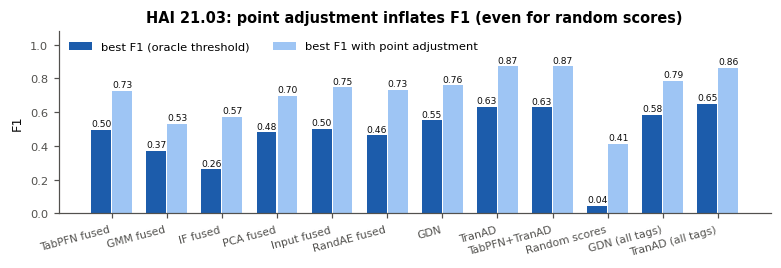

CPU times: user 2min 2s, sys: 1.49 s, total: 2min 3s
Wall time: 2min 10s


In [24]:
%%time
lit_scores = {m: score_matrix[m] for m in HEADLINE}
lit_scores["Random scores"] = np.random.default_rng(0).random(len(y_eval))
if LITERATURE_CONFIG["enabled"]:
    lit_data = SequenceData(grid_signal(LIT_TAGS))
    print(f"Literature inputs: {len(LIT_TAGS)} tags that vary in FIT (state view: {len(VIEW_FEATURES['state'])})")
    for name, runner, cfg in [("GDN", run_gdn, GDN_CONFIG), ("TranAD", run_tranad, TRANAD_CONFIG)]:
        per_seed, _ = run_cached(f"{name}-alltags", runner, lit_data, LITERATURE_CONFIG["seeds"], cfg, "all-tags")
        lit_scores[f"{name} (all tags)"] = calibrate(per_seed)["test"]
    del lit_data
    gc.collect()

lit_rows = []
for m, s in lit_scores.items():
    f, pa = best_f1(y_eval, s), point_adjusted_best_f1(y_eval, s)
    lit_rows.append({"method": m, "precision": f["precision"], "recall": f["recall"], "best_f1": f["f1"],
                     "pa_precision": pa["precision"], "pa_recall": pa["recall"], "pa_best_f1": pa["f1"],
                     "source": "this notebook (oracle threshold)"})
PUBLISHED = []     # Kim et al. do not report HAI 21.03; add published values here with their own protocol and source
literature = pd.concat([pd.DataFrame(lit_rows), pd.DataFrame(PUBLISHED)], ignore_index=True)
literature.to_csv(RUN_DIR / "results_literature_comparability.csv", index=False)
display(literature.round(4))

fig, ax = plt.subplots(figsize=(FULL_W, 2.5))
lit_names = list(lit_scores)
x = np.arange(len(lit_names))
lit_frame = pd.DataFrame(lit_rows).set_index("method").loc[lit_names]
ax.bar(x - 0.19, lit_frame["best_f1"], 0.36, color="#1c5cab", label="best F1 (oracle threshold)")
ax.bar(x + 0.19, lit_frame["pa_best_f1"], 0.36, color="#9ec5f4", label="best F1 with point adjustment")
for xi, (a, b) in enumerate(zip(lit_frame["best_f1"], lit_frame["pa_best_f1"])):
    ax.text(xi - 0.19, a + 0.01, f"{a:.2f}", ha="center", va="bottom", fontsize=6, color=INK)
    ax.text(xi + 0.19, b + 0.01, f"{b:.2f}", ha="center", va="bottom", fontsize=6, color=INK)
ax.set_xticks(x)
ax.set_xticklabels(lit_names, fontsize=7, rotation=15, ha="right")
ax.set(ylim=(0, 1.08), ylabel="F1", title=f"{DATASET}: point adjustment inflates F1 (even for random scores)")
ax.legend(loc="upper left", ncol=2)
ax.grid(False)
plt.tight_layout()
save_fig(fig, "literature_f1_point_adjustment")
plt.show()

## **F. Headline table (tidy, for the cross-dataset synthesis)**

One row per headline method with the pre-registered endpoints and their event-bootstrap CIs. The same file is written by every `*-baselines` notebook, so the paper's cross-dataset table is a `pd.concat` of the three.

In [25]:
static = main_results[main_results["threshold_mode"] == "static"].set_index("method")
head_rows = []
for m in HEADLINE:
    ci = ci_table[ci_table["method"] == m].set_index("key")
    row = {"dataset": DATASET, "method": m, "family": family_of(m)}
    for key in ["pauc", "auc", "ap", "recall", "event_recall"]:
        row[key], row[f"{key}_ci_low"], row[f"{key}_ci_high"] = ci.loc[key, ["estimate", "event_ci_low", "event_ci_high"]]
    row.update({"attacks_detected": int(static.loc[m, "attacks_detected"]), "attacks_total": len(segments),
                "test_fpr": static.loc[m, "test_fpr"], "false_alarms_per_day": static.loc[m, "false_alarms_per_day"],
                "median_ttd_s": static.loc[m, "median_ttd_s"],
                "ms_per_row": float(cost.set_index("family").loc[family_of(m), "ms_per_row"]) if family_of(m) in set(cost["family"]) else np.nan})
    if PRIMARY and m != PRIMARY:
        for key in ["pauc", "auc", "recall", "event_recall"]:
            d = paired[(paired["baseline"] == m) & (paired["key"] == key)].iloc[0]
            row[f"delta_{key}_tabpfn_minus_this"] = d["delta"]
            row[f"delta_{key}_supported"] = bool(d["event_ci_excludes_0"])
    head_rows.append(row)
headline = pd.DataFrame(head_rows)
headline.to_csv(RUN_DIR / "results_headline.csv", index=False)
display(headline.set_index("method").round(3).T)

manifest = pd.DataFrame(
    [{"file": p.relative_to(RUN_DIR).as_posix(), "MB": round(p.stat().st_size / 1e6, 3)} for p in sorted(RUN_DIR.rglob("*")) if p.is_file()]
    + [{"file": p.as_posix(), "MB": round(p.stat().st_size / 1e6, 3)} for p in sorted(FIG_DIR.glob(f"*_{FIG_VERSION}.png"))])
display(manifest)
print(f"Run directory: {RUN_DIR.resolve()} | run {RUN_FINGERPRINT}")

method,TabPFN fused,GMM fused,IF fused,PCA fused,Input fused,RandAE fused,GDN,TranAD,TabPFN+TranAD
dataset,HAI 21.03,HAI 21.03,HAI 21.03,HAI 21.03,HAI 21.03,HAI 21.03,HAI 21.03,HAI 21.03,HAI 21.03
family,TabPFN,GMM,IF,PCA,Input,RandAE,GDN,TranAD,TabPFN+TranAD
pauc,0.81,0.778,0.694,0.838,0.807,0.799,0.802,0.864,0.868
pauc_ci_low,0.754,0.699,0.647,0.79,0.757,0.749,0.742,0.808,0.81
pauc_ci_high,0.861,0.84,0.741,0.881,0.849,0.843,0.85,0.908,0.914
auc,0.914,0.9,0.828,0.915,0.891,0.889,0.849,0.903,0.92
auc_ci_low,0.876,0.854,0.773,0.872,0.844,0.843,0.792,0.853,0.877
auc_ci_high,0.945,0.935,0.874,0.947,0.927,0.925,0.894,0.94,0.952
ap,0.443,0.304,0.178,0.418,0.392,0.353,0.426,0.561,0.567
ap_ci_low,0.3,0.196,0.113,0.301,0.247,0.219,0.277,0.426,0.431


,file,MB
0,attack_segments.csv,0.003
1,bootstrap_replicates_block.parquet,1.923
2,bootstrap_replicates_event.parquet,1.976
3,config.json,0.003
4,results_bootstrap_ci.csv,0.028
5,results_cost.csv,0.001
6,results_daily_false_alarm_rate_adaptive.csv,0.008
7,results_daily_false_alarm_rate_static.csv,0.008
8,results_headline.csv,0.004
9,results_literature_comparability.csv,0.002


Run directory: /home/jaume/_DEVELOPMENT/_projects/tabular-IDS/results/HAI_baselines_v1 | run 45457feaa5


### **How to read the results**
1. **Primary endpoint:** in `paired_differences`, is the pAUC CI of `TabPFN fused − baseline` above 0 for each baseline? Filled markers are supported differences.
2. **Deployable endpoint:** in `operating_curves (a)`, at a given alarm budget (e.g. ≤ 5 false-alarm episodes per day), which family finds more attacks?
3. **Where they differ:** `per_attack_detection` and the complementarity table show whether the families find the same attacks (fusion opportunity) or different ones.
4. **Cost:** `quality_vs_cost` puts any gain next to the price per scored row.
5. **Literature table:** only for comparison with published numbers; point-adjusted F1 is not evidence (see the random-score bar).

## **Conclusions**

*See the conclusions at the end of the notebook.*


**HAI-specific reading.** HAI is the dataset with the most attacks (50), so the event-bootstrap intervals in `paired_differences` and `results_bootstrap_ci` are the ones to trust. Check the realised test FPR of every method before comparing attack counts: CAL (Aug 2020, end of `train3`) and TEST (July 2020) are different recordings, so threshold calibration may drift as on SWaT. `per_attack_detection` lists all 50 events with the attacked process (P1/P2/P3), which allows a per-process reading.

## **Conclusions**

*Run `HAI_baselines_v1` (fingerprint 45457feaa5) on `HAI_full_pipeline_v1`. 50 attack events in TEST (887 attack rows of 40,201 at 10 s). All CIs are event-bootstrap 95%; with 50 events they are wide (±0.05 on pAUC).*

**Split.** FIT 599,762 rows at 1 Hz (11 Jul – 7 Aug), CAL 25,345 rows (7–10 Aug, end of `train3`), TEST 40,201 rows (the five attack recordings, 7–31 Jul). TEST is *not* later than FIT, only the normal data is split chronologically. The CAL threshold therefore comes from a later period than the one it is applied to.

**1. Ranking (pAUC, FPR ≤ 10%).** TranAD 0.864 [0.808, 0.908] ≈ TabPFN+TranAD 0.868 > PCA 0.838 > **TabPFN 0.810 [0.754, 0.861]** ≈ Input 0.807 ≈ GDN 0.802 ≈ RandAE 0.799 > GMM 0.778 > IF 0.694. ROC-AUC: fusion 0.920, PCA 0.915, TabPFN 0.914, TranAD 0.903, GMM 0.900, Input 0.891, GDN 0.849, IF 0.828.

**2. What is supported (paired, event CI excludes 0).**
- TranAD beats TabPFN on pAUC (+0.054), AP (+0.117), recall at the static threshold (+0.218) and attacks found (48 vs 42).
- TabPFN beats IF (pAUC, AUC, recall), beats GDN on AUC (+0.065) but finds fewer attacks than GDN (42 vs 47, −0.10), and beats GMM and RandAE on AP (+0.140, +0.090).
- TabPFN is *not* distinguishable from GMM, PCA, Input or RandAE on pAUC or AUC.

**3. The untrained floor is as good as TabPFN.** `Input` (the L2 norm of the standardised features, no model) has pAUC 0.807 vs 0.810, TPR@1% FPR 0.480 vs 0.471 and best F1 0.503 vs 0.497. The zero-shot TabPFN density adds no measurable signal over a norm on HAI. On SWaT (+0.044 pAUC) and WADI A1 (+0.12) TabPFN did beat the floor, so HAI is the weak case.

**4. Operating point (static CAL 1% threshold).** All methods overshoot the 1% target on TEST: TabPFN 2.1% FPR (46.8 false-alarm episodes/day, 42/50 attacks, median detection delay 26 s), PCA 3.4% (28/day, 45/50, 16 s), Input 3.0% (30/day, 45/50, 17 s), GMM 5.6% (47/day, 47/50, 16 s), TranAD 7.0% (220/day, 48/50, 13 s). At equal or lower cost PCA and Input find more attacks and sooner than TabPFN. The adaptive threshold does not fix this (TabPFN 2.7%, 67/day). TranAD only becomes usable adaptive (3.2%, 94/day).

**5. Which attacks.** Attacks 10 and 19 (P1, 123 s and 152 s) are missed by TabPFN, GMM, PCA, TranAD and the fusion alike. TabPFN additionally misses attacks 8 (17 s), 15, 20, 25, 26 and 47, all of which TranAD finds; P1: 17/23 for TabPFN vs 21/23 for TranAD, P3: 1/2 vs 2/2. Multi-process attacks (P1+P2, P1+P3, P2+P3: 14 events) are found by every method.

**6. TabPFN+TranAD fusion.** pAUC 0.868 vs TranAD alone 0.864, 48/50 attacks in both: the fusion adds nothing over TranAD here. It beats TabPFN alone only because TranAD is in it. On A1 it raised event recall to 13/14, on SWaT and HAI it does not, so the fusion is **not** a reproducible gain and should not be claimed.

**7. GDN.** With the baseline feature set GDN has best F1 0.551; with all tags 0.583 (TranAD all tags 0.650). GDN is the weakest deep method on AUC (0.849), consistent with WADI.

**8. Point adjustment.** PA best F1: TranAD 0.872, GDN 0.760, TabPFN 0.727, Input 0.747; **random scores 0.412**. PA still makes everything look good; the raw best F1 (TabPFN 0.497, TranAD 0.631, random 0.043) is the informative number.

**9. Cost.** TabPFN 270 ms/row on GPU, GMM 0.006, PCA 0.001, Input 0.0003, TranAD 0.017 (plus 130 s training). TabPFN is ≈ 45,000× the cost of GMM for a tie.

**Bottom line.** On HAI 21.03 the zero-shot TabPFN density is a middling detector: tied with GMM, PCA, Input, RandAE and GDN, above only IF, and significantly below TranAD. It is not an early detector here (26 s vs 13–17 s). Its one consistent advantage is a lower test FPR than GMM and TranAD at the same nominal 1% threshold, but PCA and Input do as well at a fraction of the cost.

**Caveats.** (i) 50 events, many short (17–422 s) on a 10 s grid; (ii) calibration and test are from different periods and all FPRs overshoot by 2–7×; (iii) a single split, no repeat across recordings; (iv) TabPFN, GMM and the baselines share one preprocessing, so differences are about the scorer, not the features.
